# Guía de Trabajo N° 10
## Clustering particional y jerárquico: K-Means y Clustering Jerárquico
*Unidad 3: Métodos Ensemble y Aprendizaje No Supervisado*

| | |
|---|---|
| **Asignatura** | Machine Learning |
| **Unidad** | Unidad 3 — Métodos Ensemble y Aprendizaje No Supervisado |
| **Guía N°** | 10 — K-Means (desarrollo guiado) y Clustering Jerárquico (reto) |
| **Tarea** | Clustering (aprendizaje no supervisado) |
| **Modalidad** | Parte A: desarrollo guiado con código · Parte B: reto sin código · Parte C: comparación |
| **Docente** | Pedro Andres Campos Poveda |
| **Estudiante** | Camila Alison Catorceno Orellana |
| **Fecha** | 19 de noviembre de 2026 |

**Contenido**

0. Preparación del entorno
1. Parte A — Modelo 1: K-Means (desarrollo guiado, Pasos 1 a 9 e indicadores)
2. Parte B — Modelo 2: Clustering Jerárquico aglomerativo (diseño propio del procedimiento e implementación)
3. Parte C — Comparación de modelos, experimentos adicionales y conclusión
4. Preguntas teóricas
5. Referencias

> **Regla de trabajo.** El cultivar (`y_ref`) nunca se usa para entrenar ni para tomar decisiones (k, enlace, corte del árbol o estrategia de asignación). Todas las decisiones se toman con métricas internas; el ARI y el NMI aparecen solo después, como verificación didáctica.

## 0. Preparación del entorno

Se requiere Python 3 con scikit-learn (Pedregosa et al., 2011), scipy, numpy, pandas y matplotlib (`pip install -r requirements.txt`). En todos los modelos y en la división de datos se fija `random_state=42`. La celda siguiente imprime las versiones con las que se obtuvieron los resultados comentados en este notebook; con otras versiones los valores pueden variar levemente.

In [1]:
import sys
import sklearn, scipy, numpy, pandas, matplotlib
print('Python      :', sys.version.split()[0])
for lib in (sklearn, scipy, numpy, pandas, matplotlib):
    print(f'{lib.__name__:<12}:', lib.__version__)
pandas.set_option('display.width', 160)
pandas.set_option('display.max_columns', 20)

Python      : 3.13.18
sklearn     : 1.9.1
scipy       : 1.18.1
numpy       : 2.5.3
pandas      : 3.0.5
matplotlib  : 3.11.2


# Parte A — Modelo 1: K-Means (desarrollo guiado)

K-Means divide los datos en *k* grupos minimizando la inercia $J = \sum_i \sum_{x \in C_i} \lVert x - \mu_i \rVert^2$. Parte de *k* centroides iniciales elegidos con *k-means++* (Arthur & Vassilvitskii, 2007), asigna cada punto al centroide más cercano y recalcula los centroides hasta que no cambian. Supone grupos aproximadamente esféricos y de tamaño similar, y es sensible a la escala de las variables, a los atípicos y a la inicialización (Bishop, 2006; Géron, 2019; Mueller & Massaron, 2016).

### Paso 1 — Importar librerías

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score)

### Paso 2 — Cargar el dataset y revisar su calidad

Se usa el dataset **Wine** (Aeberhard & Forina, 1992), integrado en scikit-learn: 13 mediciones químicas de vinos de tres cultivares de una misma región de Italia. Se trata como un problema **no supervisado**.

In [3]:
data = load_wine(as_frame=True)
X = data.data          # 13 variables químicas
y_ref = data.target    # cultivar: SOLO para validación externa (Paso 8)
print('Dimensiones:', X.shape)
print('Tipos de dato:', X.dtypes.value_counts().to_dict())
print('Valores nulos:', X.isna().sum().sum())
print('Filas duplicadas:', X.duplicated().sum())

Dimensiones: (178, 13)
Tipos de dato: {dtype('float64'): 13}
Valores nulos: 0
Filas duplicadas: 0


**Resultado.** Hay 178 vinos y 13 variables, todas `float64`, sin valores nulos ni filas duplicadas. No hace falta imputar ni limpiar. El cultivar queda guardado aparte en `y_ref` y no vuelve a usarse hasta la validación externa del Paso 8.

### Paso 3 — Análisis exploratorio de datos (EDA)

**3a. Estadística descriptiva y escala de las variables.** K-Means usa distancias euclidianas, así que la escala de cada variable es determinante.

In [4]:
desc = X.describe().T[['mean', 'std', 'min', 'max']].round(2)
print(desc)
print()
print('Rango de la prolina:', X['proline'].min(), '-', X['proline'].max())
print('Rango del tono     :', X['hue'].min(), '-', X['hue'].max())
print(f"Varianza de la prolina / varianza del tono: {X['proline'].var() / X['hue'].var():,.0f}")

                                mean     std     min      max
alcohol                        13.00    0.81   11.03    14.83
malic_acid                      2.34    1.12    0.74     5.80
ash                             2.37    0.27    1.36     3.23
alcalinity_of_ash              19.49    3.34   10.60    30.00
magnesium                      99.74   14.28   70.00   162.00
total_phenols                   2.30    0.63    0.98     3.88
flavanoids                      2.03    1.00    0.34     5.08
nonflavanoid_phenols            0.36    0.12    0.13     0.66
proanthocyanins                 1.59    0.57    0.41     3.58
color_intensity                 5.06    2.32    1.28    13.00
hue                             0.96    0.23    0.48     1.71
od280/od315_of_diluted_wines    2.61    0.71    1.27     4.00
proline                       746.89  314.91  278.00  1680.00

Rango de la prolina: 278.0 - 1680.0
Rango del tono     : 0.48 - 1.71
Varianza de la prolina / varianza del tono: 1,898,111


**Interpretación.** Las variables están en escalas muy distintas. La prolina tiene media 746,89 y desviación 314,91 (rango 278–1680) y el magnesio media 99,74, mientras que el tono (0,48–1,71) o los fenoles no flavonoides (0,13–0,66) no llegan a 2. La varianza de la prolina es casi **1,9 millones de veces** la del tono. En una distancia euclidiana sin escalar, la prolina (y en segundo lugar el magnesio) decidiría prácticamente sola qué vinos están cerca, y las otras 11 variables no contarían. Por eso todas las variables se estandarizan (media 0, desviación 1) antes de agrupar. El efecto se mide en la tabla de indicadores del Modelo 1 (configuración «sin escalar»).

**3b. Distribuciones y valores atípicos (regla IQR).**

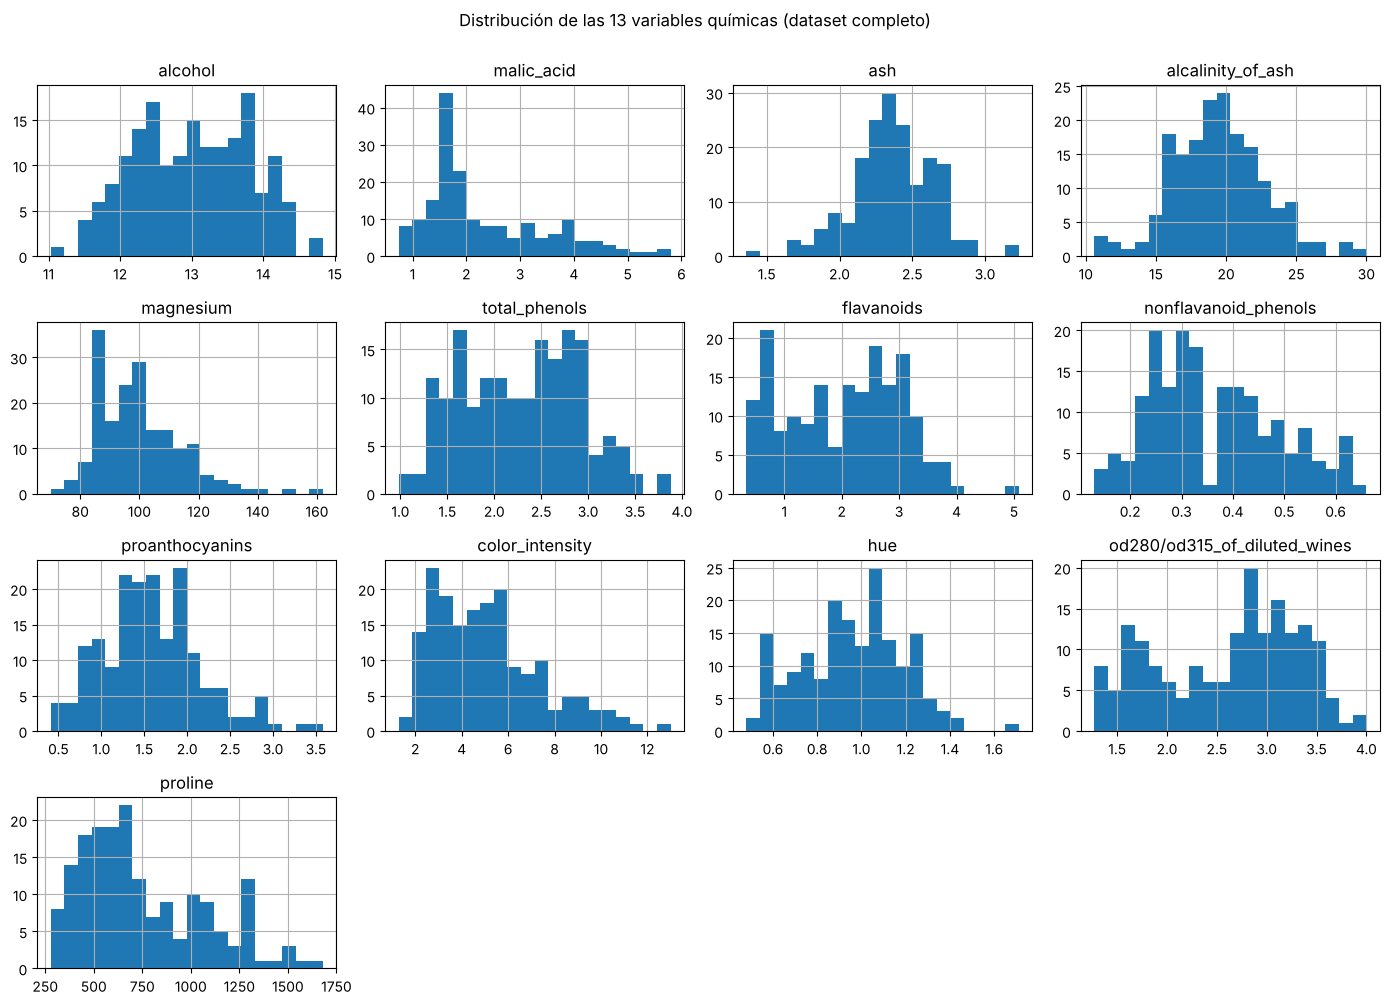

Atípicos por variable:
malic_acid           3
ash                  3
alcalinity_of_ash    4
magnesium            4
proanthocyanins      2
color_intensity      4
hue                  1
dtype: int64


In [5]:
X.hist(bins=20, figsize=(14, 10))
plt.suptitle('Distribución de las 13 variables químicas (dataset completo)', y=1.0)
plt.tight_layout(); plt.savefig('eda_histogramas.png', dpi=120); plt.show()
Q1, Q3 = X.quantile(0.25), X.quantile(0.75)
IQR = Q3 - Q1
atipicos = ((X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)).sum()
print('Atípicos por variable:')
print(atipicos[atipicos > 0])

In [6]:
# Qué vinos son atípicos (se revisan en el Paso 9)
mascara_atip = (X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)
filas_atip = mascara_atip.any(axis=1)
print('Total de valores atípicos:', int(atipicos.sum()), '| vinos con al menos uno:', int(filas_atip.sum()))
print('Índices de esos vinos:', list(X.index[filas_atip]))
print('Vinos atípicos en 2 o más variables:', list(X.index[mascara_atip.sum(axis=1) >= 2]))
print('\nAsimetría (skewness) de cada variable:')
print(X.skew().round(2).sort_values(ascending=False).to_string())

Total de valores atípicos: 21 | vinos con al menos uno: 17
Índices de esos vinos: [25, 59, 69, 73, 78, 95, 110, 115, 121, 123, 127, 137, 151, 158, 159, 166, 173]
Vinos atípicos en 2 o más variables: [59, 73, 95, 121]

Asimetría (skewness) de cada variable:
magnesium                       1.10
malic_acid                      1.04
color_intensity                 0.87
proline                         0.77
proanthocyanins                 0.52
nonflavanoid_phenols            0.45
alcalinity_of_ash               0.21
total_phenols                   0.09
flavanoids                      0.03
hue                             0.02
alcohol                        -0.05
ash                            -0.18
od280/od315_of_diluted_wines   -0.31


**Interpretación.**

- **Distribuciones:** la mayoría son unimodales y bastante simétricas (alcohol, cenizas, tono, flavonoides, fenoles totales: asimetría entre −0,31 y 0,21). El magnesio (1,10), el ácido málico (1,04), la intensidad de color (0,87) y la prolina (0,77) tienen **cola a la derecha**. En los histogramas, los flavonoides, el OD280/OD315 y la prolina muestran más de una «joroba», una primera señal de que en los datos hay subpoblaciones.
- **Atípicos:** la regla IQR marca 21 valores atípicos repartidos en 17 vinos, entre 1 y 4 por variable en ácido málico, cenizas, alcalinidad, magnesio, proantocianinas, intensidad de color y tono. Cuatro vinos (59, 73, 95 y 121) son atípicos en dos o más variables a la vez. Como K-Means promedia puntos para formar centroides, estos vinos pueden desplazarlos. Se anotan para contrastarlos con la detección por distancia del Paso 9.

**3c. Correlación entre variables.**

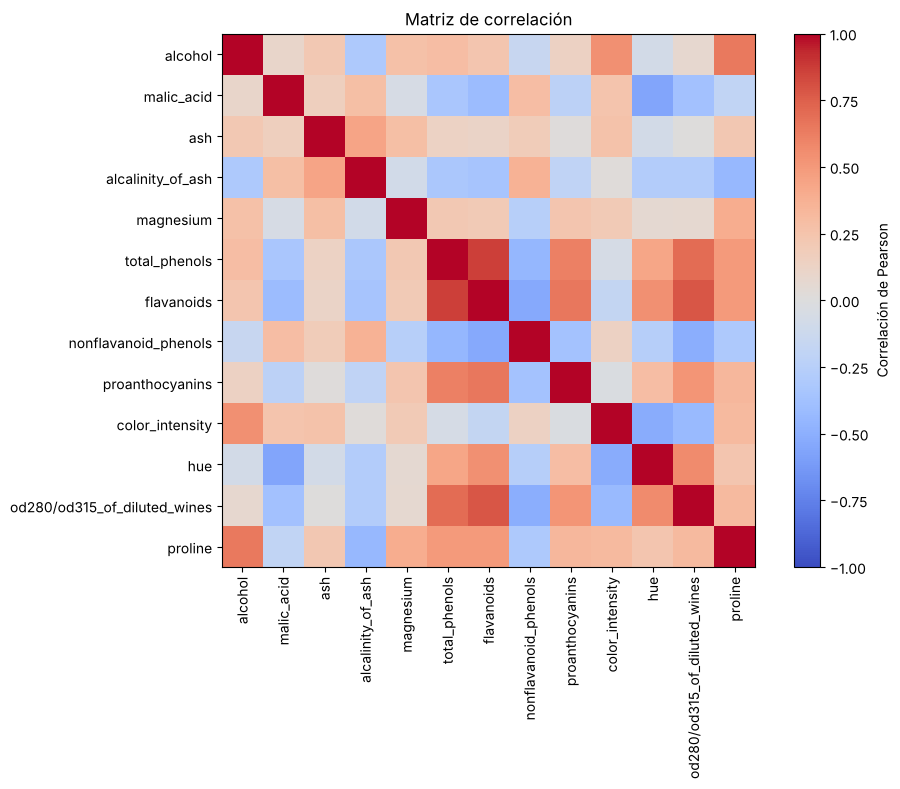

total_phenols  flavanoids                      0.86
flavanoids     od280/od315_of_diluted_wines    0.79
total_phenols  od280/od315_of_diluted_wines    0.70
flavanoids     proanthocyanins                 0.65
alcohol        proline                         0.64
dtype: float64

Correlaciones negativas más fuertes:
malic_acid       hue                    -0.56
flavanoids       nonflavanoid_phenols   -0.54
color_intensity  hue                    -0.52
dtype: float64


In [7]:
corr = X.corr()
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1); plt.colorbar(label='Correlación de Pearson')
plt.xticks(range(13), X.columns, rotation=90); plt.yticks(range(13), X.columns)
plt.title('Matriz de correlación'); plt.tight_layout(); plt.show()
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pares.abs().sort_values(ascending=False).head(5).round(2))
print('\nCorrelaciones negativas más fuertes:')
print(pares.sort_values().head(3).round(2))

**Interpretación.** Las correlaciones más altas son positivas: fenoles totales–flavonoides (0,86), flavonoides–OD280/OD315 (0,79) y fenoles totales–OD280/OD315 (0,70). Las tres variables miden en gran parte lo mismo (el contenido fenólico del vino), así que, una vez estandarizadas, ese «bloque fenólico» pesa casi como tres copias de una misma variable en la distancia euclidiana. También hay correlaciones negativas moderadas (ácido málico–tono −0,56; flavonoides–fenoles no flavonoides −0,54). Esta redundancia justifica mirar los datos en el espacio PCA, que resume variables correlacionadas en pocas componentes. En la Parte C se prueba además el PCA como preprocesamiento del jerárquico.

### Paso 4 — División entrenamiento/prueba y escalado

Aunque el clustering no tiene variable objetivo, se separa un **conjunto de prueba** (30 %) para comprobar que la estructura encontrada se mantiene en datos que el modelo no vio.

(124, 13) (54, 13)
Entrenamiento -> máx |media|: 0.0 | desviación media: 1.0
Prueba        -> máx |media|: 0.245 | desviación media: 0.95
Varianza explicada: [0.362 0.188]
Varianza acumulada con 1..13 componentes: [0.362 0.55  0.666 0.742 0.812 0.858 0.894 0.92  0.942 0.962 0.979 0.992
 1.   ]


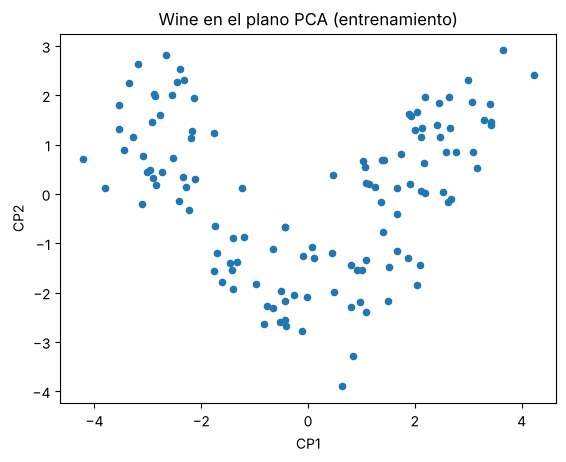

In [8]:
X_tr, X_te, y_tr_ref, y_te_ref = train_test_split(
    X, y_ref, test_size=0.3, random_state=42)
scaler = StandardScaler().fit(X_tr)   # se ajusta SOLO con entrenamiento
Xs_tr = scaler.transform(X_tr)
Xs_te = scaler.transform(X_te)
print(X_tr.shape, X_te.shape)         # (124, 13) (54, 13)

# Comprobación de que no hay fuga: solo el entrenamiento queda con media 0 y desviación 1 exactas
print('Entrenamiento -> máx |media|:', np.abs(Xs_tr.mean(axis=0)).max().round(3),
      '| desviación media:', Xs_tr.std(axis=0).mean().round(3))
print('Prueba        -> máx |media|:', np.abs(Xs_te.mean(axis=0)).max().round(3),
      '| desviación media:', Xs_te.std(axis=0).mean().round(3))

# Proyección PCA a 2D (solo para visualizar)
pca = PCA(n_components=2, random_state=42).fit(Xs_tr)
print('Varianza explicada:', pca.explained_variance_ratio_.round(3))
print('Varianza acumulada con 1..13 componentes:',
      PCA(random_state=42).fit(Xs_tr).explained_variance_ratio_.cumsum().round(3))
P_tr = pca.transform(Xs_tr)
plt.scatter(P_tr[:, 0], P_tr[:, 1], s=20)
plt.xlabel('CP1'); plt.ylabel('CP2'); plt.title('Wine en el plano PCA (entrenamiento)'); plt.show()

**Fuga de información (*data leakage*).** El `StandardScaler` aprende la media y la desviación **solo** del entrenamiento y después se *aplica* a la prueba. Por eso el entrenamiento queda con media 0 y desviación 1 exactas, y la prueba no (sus medias se alejan de 0 hasta en unas décimas). Si el escalador se ajustara con los 178 vinos, la prueba influiría en los parámetros del modelo y la evaluación posterior sería optimista: la prueba dejaría de ser realmente «datos no vistos».

Las dos primeras componentes explican ≈ 55 % de la varianza (0,362 + 0,188). La vista 2D es útil para mirar los grupos, pero incompleta: hacen falta 5 componentes para llegar al 81 %. Ya en el plano PCA se intuyen tres nubes con zonas de contacto.

### Paso 5 — Selección del número de clusters (k)

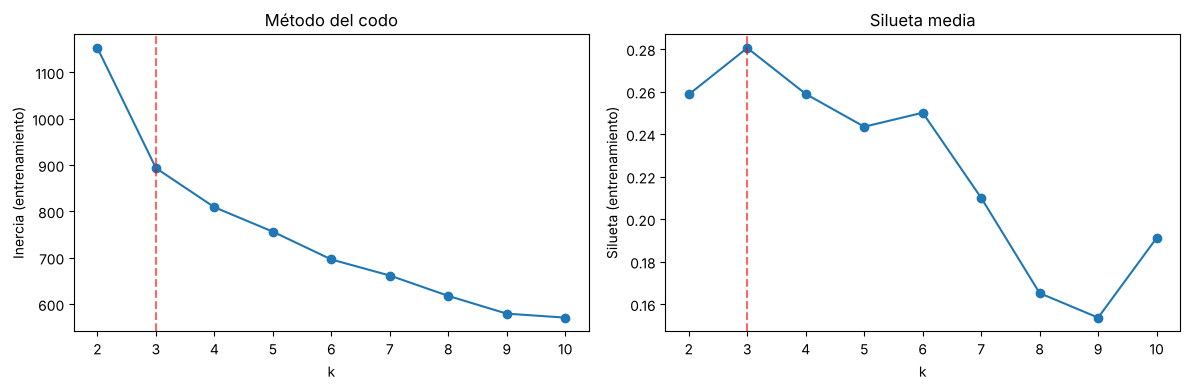

    k  inercia  silueta
0   2   1152.5    0.259
1   3    893.3    0.281
2   4    808.9    0.259
3   5    756.1    0.243
4   6    696.1    0.250
5   7    661.5    0.210
6   8    617.5    0.165
7   9    579.3    0.154
8  10    570.7    0.191

Caída de la inercia al pasar de k a k+1: [259.2  84.5  52.8  60.   34.7  44.   38.3   8.6]


In [9]:
ks = range(2, 11)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs_tr)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Xs_tr, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inercias, 'o-'); ax[0].set_title('Método del codo'); ax[0].set_xlabel('k'); ax[0].set_ylabel('Inercia (entrenamiento)')
ax[1].plot(ks, siluetas, 'o-'); ax[1].set_title('Silueta media'); ax[1].set_xlabel('k'); ax[1].set_ylabel('Silueta (entrenamiento)')
for a in ax: a.axvline(3, color='red', ls='--', alpha=0.6)
plt.tight_layout(); plt.show()
print(pd.DataFrame({'k': list(ks), 'inercia': np.round(inercias, 1),
                    'silueta': np.round(siluetas, 3)}))
print('\nCaída de la inercia al pasar de k a k+1:', np.round(-np.diff(inercias), 1))

**Elección de k.** Los dos criterios coinciden en **k = 3**:

- **Codo:** la inercia cae 259,2 unidades de k = 2 a k = 3, pero solo 84,5 de k = 3 a k = 4 y 52,8 de k = 4 a k = 5. A partir de k = 3, agregar un grupo apenas compacta más los datos.
- **Silueta** (Rousseeuw, 1987): el máximo es 0,281 en k = 3. Con k = 2 y k = 4 baja a 0,259, y desde k = 7 cae por debajo de 0,21.

La inercia por sí sola siempre baja al aumentar k, así que no basta. La silueta penaliza dividir un grupo natural (los puntos quedan cerca del grupo vecino) y también fusionar dos (los puntos quedan lejos de su propio centroide).

### Paso 6 — Entrenamiento del modelo

In [10]:
kmeans = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)
kmeans.fit(Xs_tr)
lab_tr = kmeans.labels_
print('Tamaño de cada cluster:', np.bincount(lab_tr))
# Centroides en la escala original, para interpretarlos
cent = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=X.columns)
print(cent[['alcohol', 'flavanoids', 'color_intensity', 'proline']].round(2))

Tamaño de cada cluster: [43 45 36]
   alcohol  flavanoids  color_intensity  proline
0    13.65        3.01             5.34  1071.84
1    12.21        2.00             2.93   510.38
2    13.08        0.81             7.09   621.25


In [11]:
# Perfil completo: centroides en escala original y en unidades estandarizadas (z)
perfil_km = cent.T.round(2)
perfil_km.columns = [f'cluster {c} (original)' for c in range(3)]
z_km = pd.DataFrame(kmeans.cluster_centers_, columns=X.columns).T.round(2)
z_km.columns = [f'cluster {c} (z)' for c in range(3)]
display(pd.concat([perfil_km, z_km], axis=1))

,cluster 0 (original),cluster 1 (original),cluster 2 (original),cluster 0 (z),cluster 1 (z),cluster 2 (z)
alcohol,13.65,12.21,13.08,0.82,-0.90,0.14
malic_acid,1.98,2.04,3.36,-0.38,-0.33,0.88
ash,2.46,2.24,2.41,0.36,-0.48,0.17
alcalinity_of_ash,17.38,20.22,21.13,-0.61,0.21,0.47
magnesium,110.00,93.40,99.33,0.60,-0.49,-0.10
total_phenols,2.86,2.21,1.65,0.90,-0.10,-0.96
flavanoids,3.01,2.00,0.81,1.00,-0.00,-1.19
nonflavanoid_phenols,0.30,0.35,0.45,-0.47,-0.09,0.68
proanthocyanins,1.95,1.66,1.09,0.61,0.11,-0.87
color_intensity,5.34,2.93,7.09,0.17,-0.94,0.97


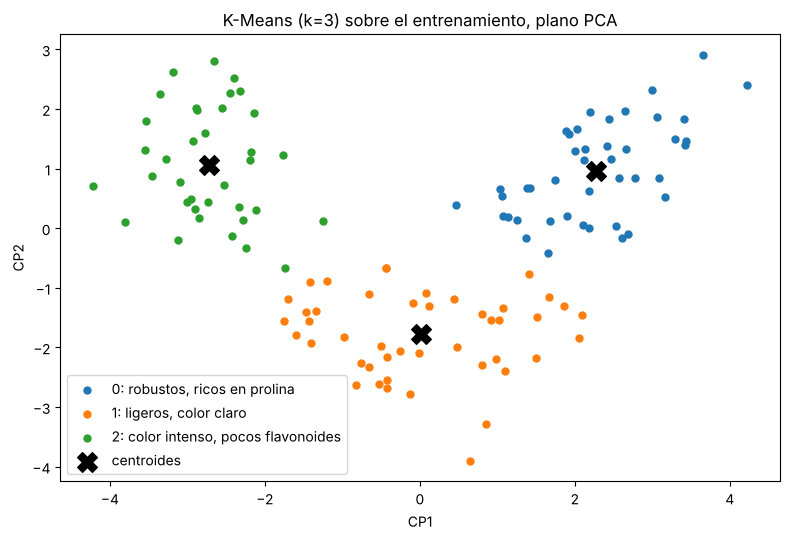

In [12]:
# Grupos de K-Means en el plano PCA (entrenamiento), con los centroides proyectados
C_pca = pca.transform(kmeans.cluster_centers_)
nombres_km = {0: '0: robustos, ricos en prolina', 1: '1: ligeros, color claro', 2: '2: color intenso, pocos flavonoides'}
fig, ax = plt.subplots(figsize=(8, 5.5))
for c in range(3):
    ax.scatter(P_tr[lab_tr == c, 0], P_tr[lab_tr == c, 1], s=25, label=nombres_km[c])
ax.scatter(C_pca[:, 0], C_pca[:, 1], c='black', marker='X', s=200, label='centroides')
ax.set_xlabel('CP1'); ax.set_ylabel('CP2'); ax.set_title('K-Means (k=3) sobre el entrenamiento, plano PCA')
ax.legend(); plt.tight_layout(); plt.show()

**Interpretación de los centroides.** Los números de cluster son arbitrarios. Cada grupo se describe con las variables en las que su centroide más se aleja de la media (columnas *z*, en desviaciones estándar):

| Cluster | n | Rasgos distintivos (escala original, z entre paréntesis) | Nombre propuesto |
|---|---|---|---|
| 0 | 43 | Prolina 1071,8 (+1,10), flavonoides 3,01 (+1,00), fenoles totales 2,86 (+0,90), alcohol 13,65 (+0,82), magnesio 110 (+0,60) | **Vinos robustos, ricos en prolina y fenoles** |
| 1 | 45 | Intensidad de color 2,93 (−0,94), alcohol 12,21 (−0,90), prolina 510,4 (−0,75), cenizas y magnesio bajos | **Vinos ligeros, de color claro** |
| 2 | 36 | OD280/OD315 1,65 (−1,31), flavonoides 0,81 (−1,19), tono 0,70 (−1,10), intensidad de color 7,09 (+0,97), ácido málico 3,36 (+0,88) | **Vinos de color intenso, pobres en flavonoides y más ácidos** |

En el plano PCA, la CP1 (cargada en flavonoides, fenoles totales y OD280) ordena los grupos 2 → 1 → 0 según su contenido fenólico, y la CP2 (cargada en intensidad de color, alcohol y prolina) separa abajo al grupo de vinos ligeros. En 2D los grupos se ven bastante separados, aunque el grupo 1 se acerca a los otros dos en sus extremos. Como esta vista recoge solo el 55 % de la varianza, la superposición en 13 dimensiones es mayor, lo que concuerda con una silueta moderada.

### Paso 7 — Testeo y validación

**7a. Asignar la prueba y comparar métricas internas.** K-Means sí tiene `predict()`: asigna cada punto nuevo al centroide más cercano.

In [13]:
lab_te = kmeans.predict(Xs_te)
def metricas(Xs, lab):
    return {'silueta': round(silhouette_score(Xs, lab), 3),
            'davies_bouldin': round(davies_bouldin_score(Xs, lab), 3),
            'calinski_harabasz': round(calinski_harabasz_score(Xs, lab), 1)}
print('Entrenamiento:', metricas(Xs_tr, lab_tr), '| inercia', round(kmeans.inertia_, 1))
print('Prueba       :', metricas(Xs_te, lab_te))
print('Tamaños en la prueba:', np.bincount(lab_te))

Entrenamiento: {'silueta': 0.281, 'davies_bouldin': 1.41, 'calinski_harabasz': 48.7} | inercia 893.3
Prueba       : {'silueta': 0.296, 'davies_bouldin': 1.265, 'calinski_harabasz': 23.7}
Tamaños en la prueba: [19 20 15]


**7b. Estabilidad frente a la inicialización.** Se entrena con 10 semillas distintas (con `n_init=1`, es decir, una sola inicialización cada vez) y se mide el acuerdo (ARI) entre sus asignaciones en la prueba.

In [14]:
aris = [adjusted_rand_score(lab_te,
        KMeans(3, n_init=1, random_state=s).fit(Xs_tr).predict(Xs_te))
        for s in range(10)]
print('ARI entre semillas:', np.round(aris, 3), '| media', round(np.mean(aris), 3))

# Complemento: ¿cambia algo en el entrenamiento?
modelos_s = [KMeans(3, n_init=1, random_state=s).fit(Xs_tr) for s in range(10)]
print('Inercia por semilla      :', np.round([m.inertia_ for m in modelos_s], 2))
print('ARI en entrenamiento vs. modelo final:', np.round([adjusted_rand_score(lab_tr, m.labels_) for m in modelos_s], 3))

ARI entre semillas: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.] | media 1.0
Inercia por semilla      : [894.6  894.6  894.46 894.6  893.65 894.46 894.6  894.46 893.33 893.65]
ARI en entrenamiento vs. modelo final: [0.949 0.924 0.949 0.924 0.974 0.949 0.949 0.949 1.    0.974]


**7c. Consistencia de la estructura.** Se agrupa la prueba de forma independiente y se compara con lo que predice el modelo entrenado (idea de la *fuerza de predicción*; Tibshirani & Walther, 2005; Burkov, 2019).

In [15]:
km_te = KMeans(3, n_init=10, random_state=42).fit(Xs_te)
print('ARI (modelo de entrenamiento vs. modelo propio de la prueba):',
      round(adjusted_rand_score(lab_te, km_te.labels_), 3))

ARI (modelo de entrenamiento vs. modelo propio de la prueba): 0.884


In [16]:
tabla_7 = pd.DataFrame([
    {'Conjunto': f'Entrenamiento (n = {len(Xs_tr)})', **metricas(Xs_tr, lab_tr), 'Estabilidad (ARI)': '—'},
    {'Conjunto': f'Prueba (n = {len(Xs_te)})', **metricas(Xs_te, lab_te),
     'Estabilidad (ARI)': f'Semillas: {np.mean(aris):.3f} · Consistencia: {adjusted_rand_score(lab_te, km_te.labels_):.3f}'}
]).set_index('Conjunto')
tabla_7

,silueta,davies_bouldin,calinski_harabasz,Estabilidad (ARI)
Conjunto,,,,
Entrenamiento (n = 124),0.281,1.410,48.7,—
Prueba (n = 54),0.296,1.265,23.7,Semillas: 1.000 · Consistencia: 0.884


**Cómo leer estos resultados.**

- **Generalización:** la silueta (0,281 → 0,296) y el índice de Davies-Bouldin (Davies & Bouldin, 1979; 1,410 → 1,265) son similares, e incluso algo mejores, en la prueba. La estructura encontrada en el entrenamiento **se mantiene** en datos no vistos; no hay indicios de que el modelo haya «memorizado» particularidades del entrenamiento.
- **Calinski-Harabasz** baja de 48,7 a 23,7 porque el índice se multiplica por $(n-k)/(k-1)$: crece con el número de puntos (Caliński & Harabasz, 1974). Con 124 y 54 vinos, **no se compara** entre conjuntos. Solo sirve para comparar modelos sobre el mismo conjunto.
- **Silueta ≈ 0,3:** indica grupos reales pero con cierta superposición, un valor razonable en datos químicos de 13 dimensiones.
- **Estabilidad:** las 10 semillas dan exactamente la misma partición de la prueba (ARI = 1,000). En el entrenamiento, la inercia varía solo entre 893,33 y 894,60 y el ARI frente al modelo final entre 0,924 y 1,000: las semillas solo cambian de grupo a unos pocos vinos de frontera. Aun con una sola inicialización, *k-means++* llega a la misma solución práctica. Con `n_init=10` el riesgo de un mal óptimo local es despreciable.
- **Consistencia = 0,884:** si se agrupa la prueba por separado, sale casi la misma partición que predice el modelo de entrenamiento. Los grupos son una propiedad de los datos, no un artefacto de la muestra de entrenamiento.

### Paso 8 — Métricas del modelo y validación externa

Solo ahora, con el modelo ya elegido y entrenado, se compara con el cultivar (verificación didáctica).

ARI prueba vs. cultivar: 0.946
NMI prueba vs. cultivar: 0.935
cluster    0   1   2
cultivar            
0         19   0   0
1          0  20   1
2          0   0  14

Entrenamiento (solo para contexto):
cluster    0   1   2
cultivar            
0         40   0   0
1          3  45   2
2          0   0  34


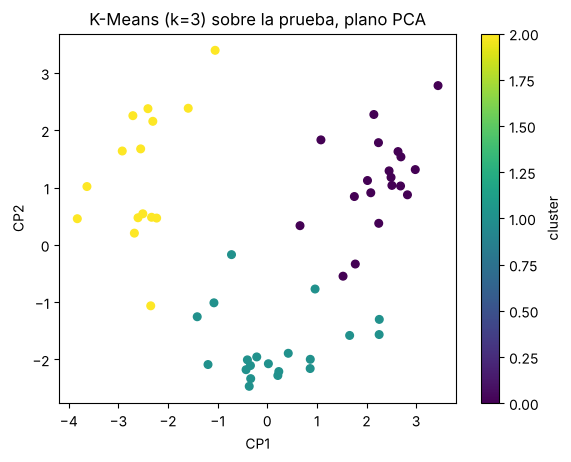

In [17]:
print('ARI prueba vs. cultivar:', round(adjusted_rand_score(y_te_ref, lab_te), 3))
print('NMI prueba vs. cultivar:', round(normalized_mutual_info_score(y_te_ref, lab_te), 3))
print(pd.crosstab(y_te_ref, lab_te, rownames=['cultivar'], colnames=['cluster']))
print('\nEntrenamiento (solo para contexto):')
print(pd.crosstab(y_tr_ref, lab_tr, rownames=['cultivar'], colnames=['cluster']))
P_te = pca.transform(Xs_te)
plt.scatter(P_te[:, 0], P_te[:, 1], c=lab_te, cmap='viridis', s=30)
plt.xlabel('CP1'); plt.ylabel('CP2')
plt.title('K-Means (k=3) sobre la prueba, plano PCA'); plt.colorbar(label='cluster'); plt.show()

**Resultado.** **ARI = 0,946** y **NMI = 0,935** en la prueba. La correspondencia es directa (cluster 0 ↔ cultivar 0, 1 ↔ 1, 2 ↔ 2): de los 54 vinos de prueba, solo uno del cultivar 1 queda en el grupo 2. Sin haber usado nunca la etiqueta, K-Means recupera casi exactamente los tres cultivares. En el entrenamiento ocurre lo mismo, y los pocos errores (5 de 124) también son vinos del cultivar 1, el más heterogéneo: es el grupo de vinos «ligeros» y comparte frontera con los otros dos.

### Paso 9 — (Complementario) Detección de anomalías

Un vino muy alejado de su centroide más cercano no encaja en ninguno de los grupos. Se usa como umbral el percentil 97 de esas distancias en el entrenamiento.

In [18]:
d_tr = kmeans.transform(Xs_tr).min(axis=1)   # distancia al centroide más cercano
umbral = np.percentile(d_tr, 97)
d_te = kmeans.transform(Xs_te).min(axis=1)
print('Umbral:', round(umbral, 2), '| anomalías en prueba:', int((d_te > umbral).sum()))
print(X_te[d_te > umbral])

Umbral: 4.78 | anomalías en prueba: 1
     alcohol  malic_acid  ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
158    14.34        1.68  2.7               25.0       98.0            2.8        1.31                  0.53              2.7             13.0  0.57   

     od280/od315_of_diluted_wines  proline  
158                          1.96    660.0  


In [19]:
# Contraste con los atípicos univariados detectados por IQR en el Paso 3
idx_anom_te = X_te.index[d_te > umbral]
for i in idx_anom_te:
    print(f'Vino {i}: ¿atípico por IQR? {bool(filas_atip[i])} -> variables:',
          list(mascara_atip.columns[mascara_atip.loc[i]]),
          f"| intensidad de color = {X.loc[i, 'color_intensity']} (máximo del dataset = {X['color_intensity'].max()})")
idx_anom_tr = X_tr.index[d_tr > umbral]
print('\nAnomalías en el entrenamiento (d > umbral):', list(idx_anom_tr))
print('¿Todas son atípicas por IQR?', bool(filas_atip[idx_anom_tr].all()))
print('Variables atípicas de cada una:', {i: list(mascara_atip.columns[mascara_atip.loc[i]]) for i in idx_anom_tr})

Vino 158: ¿atípico por IQR? True -> variables: ['color_intensity'] | intensidad de color = 13.0 (máximo del dataset = 13.0)

Anomalías en el entrenamiento (d > umbral): [69, 95, 59, 121]
¿Todas son atípicas por IQR? True
Variables atípicas de cada una: {69: ['magnesium'], 95: ['magnesium', 'proanthocyanins'], 59: ['ash', 'alcalinity_of_ash'], 121: ['ash', 'alcalinity_of_ash']}


**Resultado.** Con el percentil 97 como umbral (≈ 4,78) aparece **1 vino atípico** en la prueba, el vino 158. **Sí coincide** con la regla IQR: tiene la intensidad de color máxima del dataset (13,00), y además un tono muy bajo (0,57) y alcalinidad alta (25). En el entrenamiento, los cuatro vinos que superan el umbral (59, 69, 95 y 121) también estaban en la lista IQR, y tres de ellos (59, 95 y 121) eran atípicos en dos o más variables.

La distancia al centroide resume las 13 variables a la vez (detección multivariada). Por eso marca sobre todo a los vinos que se salen de lo normal en varias variables, y no a cualquier vino con un solo valor extremo. Estos mismos vinos reaparecen en la Parte B como los «puntos sueltos» que aíslan algunos enlaces del jerárquico.

### Indicadores del Modelo 1

Para que las configuraciones sean comparables, **todas las métricas internas se calculan en el mismo espacio estandarizado** (`Xs_tr`/`Xs_te`), incluso para el modelo entrenado sin escalar. La inercia es la del propio modelo en su espacio de entrenamiento. El ARI y el NMI se miden en la prueba.

In [20]:
def fila_kmeans(nombre, k, Xtr_modelo, Xte_modelo):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xtr_modelo)
    lt = m.predict(Xte_modelo)
    mt = metricas(Xs_te, lt)
    return {'Configuración': nombre, 'Inercia (train)': round(m.inertia_, 1),
            'Silueta (train)': round(silhouette_score(Xs_tr, m.labels_), 3),
            'Silueta (test)': mt['silueta'], 'DB (test)': mt['davies_bouldin'],
            'CH (test)': mt['calinski_harabasz'],
            'ARI ext. (test)': round(adjusted_rand_score(y_te_ref, lt), 3),
            'NMI ext. (test)': round(normalized_mutual_info_score(y_te_ref, lt), 3)}, m

filas_m1 = []
for k in (2, 3, 4):
    f, _ = fila_kmeans(f'K-Means k = {k}' + (' (elegido)' if k == 3 else ''), k, Xs_tr, Xs_te)
    filas_m1.append(f)
f, km_raw = fila_kmeans('K-Means k = 3 sin escalar', 3, X_tr, X_te)
filas_m1.append(f)
indicadores_m1 = pd.DataFrame(filas_m1).set_index('Configuración')
display(indicadores_m1)

# El modelo sin escalar, mirado en su propio espacio (sin estandarizar)
print('Sin escalar -> silueta medida en el espacio ORIGINAL: train',
      round(silhouette_score(X_tr, km_raw.labels_), 3), '| test', round(silhouette_score(X_te, km_raw.predict(X_te)), 3))
print('Prolina por grupo del modelo sin escalar:')
print(X_tr.groupby(km_raw.labels_)['proline'].agg(['count', 'min', 'max']).round(0))

,Inercia (train),Silueta (train),Silueta (test),DB (test),CH (test),ARI ext. (test),NMI ext. (test)
Configuración,,,,,,,
K-Means k = 2,1152.5,0.259,0.247,1.562,20.1,0.372,0.480
K-Means k = 3 (elegido),893.3,0.281,0.296,1.265,23.7,0.946,0.935
K-Means k = 4,808.9,0.259,0.225,1.632,17.2,0.831,0.859
K-Means k = 3 sin escalar,1527621.0,0.090,0.144,3.015,9.8,0.456,0.516


Sin escalar -> silueta medida en el espacio ORIGINAL: train 0.566 | test 0.575
Prolina por grupo del modelo sin escalar:
   count    min     max
0     42  607.0   937.0
1     30  985.0  1547.0
2     52  278.0   600.0


**Interpretación.**

- **k = 3** es el mejor en todas las métricas de prueba: mayor silueta (0,296), menor Davies-Bouldin (1,265), mayor Calinski-Harabasz (23,7) y la mejor validación externa (ARI 0,946).
- **k = 2** fusiona dos grupos naturales: la silueta baja a 0,247 y el ARI cae a 0,372. **k = 4** parte uno de ellos en dos: la silueta de prueba baja a 0,225 y Davies-Bouldin sube a 1,632. Las métricas internas detectan ambos errores sin necesidad de etiquetas.
- **Sin escalar**, la inercia (≈ 1,5 millones) está en unidades de prolina² y no es comparable. Los grupos resultantes son simplemente tres **franjas de prolina** (278–600, 607–937 y 985–1547). Medida en su propio espacio sin escalar, la silueta parece excelente (0,566 en train). Es un espejismo: mide la separación sobre una sola variable. En el espacio estandarizado, donde las 13 variables cuentan, la silueta es 0,090/0,144, Davies-Bouldin sube a 3,015 y el ARI baja a 0,456. **Escalar no es opcional en este dataset.**

# Parte B — Modelo 2: Clustering Jerárquico aglomerativo (reto)

En el clustering jerárquico aglomerativo, cada vino empieza como un grupo propio y en cada paso se fusionan los dos grupos más cercanos, hasta que queda uno solo. El resultado es un **dendrograma**, que se corta a la altura deseada para obtener *k* grupos. La distancia entre grupos depende del **criterio de enlace** (Murphy, 2012): simple (par más cercano), completo (par más lejano), promedio (promedio de todos los pares) o Ward, que fusiona el par que menos aumenta la varianza intra-grupo (Ward, 1963).

## B.1 Diseño del procedimiento (propio)

| # | Paso | Decisión | Justificación |
|---|---|---|---|
| 1 | **Datos** | Reutilizar `Xs_tr` y `Xs_te` del Paso 4 (misma división 70/30 y mismo `StandardScaler`, ajustado solo con entrenamiento). | Comparación justa con K-Means y sin fuga de información. Con otra división o escalado, cualquier diferencia podría deberse a los datos y no al modelo. |
| 2 | **EDA de distancias** | Calcular `pdist(Xs_tr)` (euclidiana, 124·123/2 = 7 626 pares), graficar su histograma e identificar los vinos más alejados del resto. | El jerárquico trabaja directamente sobre esta matriz. Su forma anticipa si habrá grupos bien separados y qué puntos aislados pueden «secuestrar» un corte. Además, su tamaño, O(n²), es el límite de escala del método. |
| 3 | **Cuatro árboles** | `linkage(Xs_tr, método)` con ward, complete, average y single (métrica euclidiana). | Cada enlace define una distancia distinta entre grupos y produce formas distintas. Ward exige distancia euclidiana porque trabaja con sumas de cuadrados. |
| 4 | **Fidelidad del árbol** | Correlación cofenética de cada árbol (`cophenet`). | Mide cuánto respetan las alturas del árbol las distancias originales (Sokal & Rohlf, 1962). Es un criterio **secundario**: evalúa el árbol completo, no la partición en *k* grupos. |
| 5 | **Corte provisional en k = 3** | `fcluster(Z, 3, 'maxclust')` y registro de tamaños y silueta de entrenamiento. | Permite comparar los enlaces con el mismo *k* que sugirió el Paso 5. El *k* definitivo se revisa en el paso 7. |
| 6 | **Regla de tamaño y elección del enlace** | Un enlace es aceptable solo si su grupo más pequeño tiene al menos el 10 % de los vinos de entrenamiento (⌈0,10·124⌉ = 13). Entre los aceptables se elige el de **mayor silueta de entrenamiento**. | Una partición «grupo gigante + puntos sueltos» separa atípicos, no grupos. El criterio es interno: no usa el cultivar. |
| 7 | **Elección de k y dendrograma** | Con el enlace elegido: (a) alturas de las últimas fusiones, donde el **mayor salto** indica dónde cortar; (b) silueta para k = 2…10 aplicando la regla de tamaño. Dibujar el dendrograma truncado (`truncate_mode='lastp'`) y marcar la línea de corte. | El salto de altura es el criterio propio del jerárquico: un corte en una zona «larga» del árbol separa grupos que el algoritmo tardó mucho en fusionar. La silueta lo confirma con la misma métrica usada para K-Means. |
| 8 | **Asignación de la prueba** | El jerárquico no tiene `predict()`. Estrategia principal (la de la guía): **k-NN con k = 5** entrenado con `Xs_tr` y las etiquetas del jerárquico. Alternativa a contrastar en la Parte C: **centroide más cercano**. | El k-NN respeta la forma local de los grupos (útil para enlaces que forman cadenas). El centroide es coherente con Ward, que construye grupos compactos alrededor de su media. Se comparan con métricas internas de prueba. |
| 9 | **Métricas** | Silueta, Davies-Bouldin y Calinski-Harabasz en entrenamiento y prueba; ARI y NMI frente al cultivar solo en prueba. | Las mismas métricas que en la Parte A, para que la comparación sea directa. |
| 10 | **Interpretación** | Perfil medio de cada grupo en escala original, renumerando los grupos para alinearlos con los de K-Means (emparejamiento de máxima coincidencia entre ambas particiones, sin usar el cultivar). | Los números de grupo son arbitrarios. Alinearlos permite comparar perfil con perfil. |

### Pseudocódigo

```text
ENTRADA:    Xs_tr, Xs_te (escalados con el scaler del Paso 4), y_te_ref (solo validación externa)
PARÁMETROS: enlaces = [ward, complete, average, single], k_ini = 3, tam_min = ⌈0,10 · n_tr⌉

d ← distancias_euclidianas_por_pares(Xs_tr)
DIBUJAR histograma(d); LISTAR los vinos con mayor distancia media al resto

PARA cada enlace EN enlaces:
    Z[enlace] ← matriz_de_enlace(Xs_tr, enlace)
    c         ← correlación_cofenética(Z[enlace], d)
    lab       ← cortar_árbol(Z[enlace], k_ini)
    lab_te    ← kNN(k = 5).entrenar(Xs_tr, lab).predecir(Xs_te)
    REGISTRAR enlace, c, tamaños(lab), silueta(Xs_tr, lab),
              silueta(Xs_te, lab_te), DB(Xs_te, lab_te), ARI(y_te_ref, lab_te)

candidatos ← { enlace : min(tamaños(lab)) ≥ tam_min }
enlace*    ← argmax_{candidatos} silueta(Xs_tr, lab)          # decisión SIN etiquetas

h        ← alturas de fusión de Z[enlace*]
salto(k) ← h[n−k+1] − h[n−k]   para k = 2..10                  # cortar entre esas alturas deja k grupos
k*       ← argmax salto(k)
VERIFICAR k* con silueta(Xs_tr, cortar_árbol(Z[enlace*], k)) y tam_min, para k = 2..10
DIBUJAR dendrograma(Z[enlace*], truncado) Y MARCAR la línea de corte

lab_tr  ← cortar_árbol(Z[enlace*], k*)
lab_tr  ← renumerar(lab_tr) para alinearlo con K-Means
lab_te  ← kNN(k = 5).entrenar(Xs_tr, lab_tr).predecir(Xs_te)

REPORTAR métricas_internas(Xs_tr, lab_tr), métricas_internas(Xs_te, lab_te)
REPORTAR ARI(y_te_ref, lab_te), NMI(y_te_ref, lab_te)
REPORTAR perfil_medio_escala_original(X_tr, lab_tr) frente a centroides de K-Means
```

## B.2 Dataset y EDA de distancias

Pares de vinos: 7626
Mínima / mediana / máxima: [ 1.17  5.   11.08]
Media: 4.91 | desviación: 1.44 | referencia sqrt(2*13) = 5.1
Pares a más de 9 unidades: 7
Vinos más alejados del resto (distancia media): {121: 6.94, 59: 6.71, 95: 6.33, 69: 6.32, 14: 6.17, 73: 6.17}


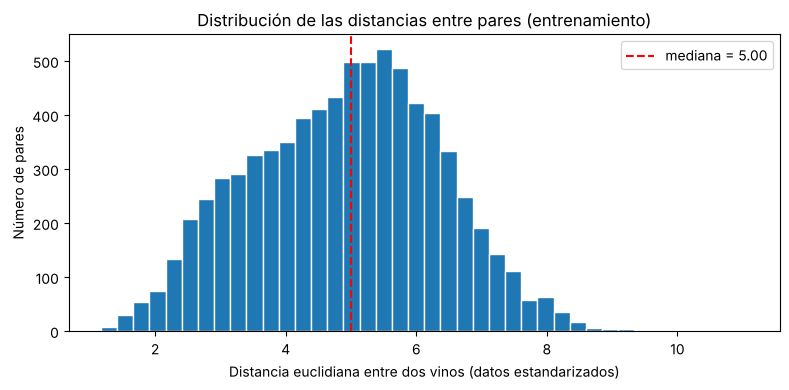

In [21]:
import time
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, cophenet, fcluster, dendrogram
from scipy.optimize import linear_sum_assignment
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.cluster import AgglomerativeClustering

d_pares = pdist(Xs_tr, metric='euclidean')          # forma condensada: n(n-1)/2 valores
print('Pares de vinos:', len(d_pares))
print('Mínima / mediana / máxima:', np.round([d_pares.min(), np.median(d_pares), d_pares.max()], 2))
print('Media:', round(d_pares.mean(), 2), '| desviación:', round(d_pares.std(), 2),
      '| referencia sqrt(2*13) =', round(np.sqrt(2 * 13), 2))
print('Pares a más de 9 unidades:', int((d_pares > 9).sum()))

dist_media = pd.Series(squareform(d_pares).mean(axis=1), index=X_tr.index).sort_values(ascending=False)
print('Vinos más alejados del resto (distancia media):', dist_media.head(6).round(2).to_dict())

plt.figure(figsize=(8, 4))
plt.hist(d_pares, bins=40, edgecolor='white')
plt.axvline(np.median(d_pares), color='red', ls='--', label=f'mediana = {np.median(d_pares):.2f}')
plt.xlabel('Distancia euclidiana entre dos vinos (datos estandarizados)'); plt.ylabel('Número de pares')
plt.title('Distribución de las distancias entre pares (entrenamiento)'); plt.legend()
plt.tight_layout(); plt.show()

**Interpretación.** Hay 7 626 distancias entre pares, entre 1,17 y 11,08, con mediana 5,00. La media (4,91) está cerca de $\sqrt{2\cdot 13} \approx 5{,}10$, la distancia esperada entre dos puntos estandarizados al azar en 13 dimensiones. El histograma es **una sola montaña**, sin un modo separado de distancias «cortas» (dentro de un grupo) y otro de distancias «largas» (entre grupos). Esto es la concentración de distancias propia de la alta dimensión: los grupos existen, pero se superponen, lo que concuerda con una silueta ≈ 0,3.

La cola derecha es muy delgada (solo 7 pares superan 9 unidades) y la forman unos pocos vinos aislados. Los vinos con mayor distancia media al resto son el 121, 59, 95, 69, 14 y 73. Todos salvo el 14 son atípicos de la regla IQR, y los cuatro primeros son exactamente las anomalías del Paso 9. Un enlace que mire distancias extremas (simple, completo o promedio) los fusionará muy tarde, y al cortar el árbol en pocos grupos pueden aparecer como «grupos» de 1 a 4 vinos.

## B.3 Entrenamiento con cuatro enlaces, cofenética y corte provisional en k = 3

In [22]:
def metricas_seguras(Xs, lab):
    # La silueta y Davies-Bouldin no están definidas si todo cae en un solo grupo
    if len(np.unique(lab)) < 2:
        return {'silueta': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    return metricas(Xs, lab)

ENLACES = ['ward', 'complete', 'average', 'single']
TAM_MIN = int(np.ceil(0.10 * len(Xs_tr)))
Z, filas_m2 = {}, []
for enlace in ENLACES:
    Z[enlace] = linkage(Xs_tr, method=enlace, metric='euclidean')
    c_cof, _ = cophenet(Z[enlace], d_pares)
    lab_e = fcluster(Z[enlace], t=3, criterion='maxclust') - 1
    lab_e_te = KNeighborsClassifier(n_neighbors=5).fit(Xs_tr, lab_e).predict(Xs_te)
    m_tr, m_te = metricas_seguras(Xs_tr, lab_e), metricas_seguras(Xs_te, lab_e_te)
    tam = np.bincount(lab_e)
    pequenos = [list(X_tr.index[lab_e == g]) for g in range(len(tam)) if tam[g] < TAM_MIN]
    filas_m2.append({'Enlace': enlace, 'Cofenética': round(c_cof, 3),
                     'Tamaños de grupo': ' / '.join(map(str, sorted(tam, reverse=True))),
                     f'Mín. ≥ {TAM_MIN}': bool(tam.min() >= TAM_MIN),
                     'Silueta train': m_tr['silueta'], 'Silueta test': m_te['silueta'],
                     'DB test': m_te['davies_bouldin'], 'Grupos en test': len(np.unique(lab_e_te)),
                     'ARI test': round(adjusted_rand_score(y_te_ref, lab_e_te), 3),
                     'NMI test': round(normalized_mutual_info_score(y_te_ref, lab_e_te), 3)})
    print(f'{enlace:<9} vinos en grupos pequeños (< {TAM_MIN}):', pequenos)

indicadores_m2 = pd.DataFrame(filas_m2).set_index('Enlace')
indicadores_m2.fillna('n. d.')

ward      vinos en grupos pequeños (< 13): []
complete  vinos en grupos pequeños (< 13): [[25, 73, 121, 71]]
average   vinos en grupos pequeños (< 13): [[25, 73, 121], [59]]
single    vinos en grupos pequeños (< 13): [[78, 69, 95], [73]]


,Cofenética,Tamaños de grupo,Mín. ≥ 13,Silueta train,Silueta test,DB test,Grupos en test,ARI test,NMI test
Enlace,,,,,,,,,
ward,0.653,46 / 40 / 38,True,0.275,0.286,1.282,3,0.836,0.826
complete,0.688,82 / 38 / 4,False,0.226,0.278,1.423,2,0.432,0.574
average,0.747,120 / 3 / 1,False,0.159,n. d.,n. d.,1,0.000,0.000
single,0.524,120 / 3 / 1,False,0.162,n. d.,n. d.,1,0.000,0.000


**Indicadores del Modelo 2 y análisis de la «pista».** El enlace con **mayor** correlación cofenética es el **promedio (0,747)**, y aun así su corte en 3 grupos es inútil: 120 / 3 / 1. Solo separa a los vinos 25, 73 y 121 por un lado y al 59 por otro, los atípicos detectados en el EDA. En la prueba, el k-NN asigna los 54 vinos al grupo grande: la silueta y Davies-Bouldin quedan **no definidas** (un solo grupo) y el ARI es 0. El enlace **simple** (0,524) produce el mismo patrón, aislando a 69, 78, 95 y 73, porque el encadenamiento une casi todo antes de llegar a los extremos. El **completo** (0,688) mejora un poco (82 / 38 / 4), pero sigue gastando un grupo en cuatro vinos atípicos (25, 71, 73 y 121), y su ARI es 0,432.

**Ward** tiene una cofenética *menor* (0,653) y es el único que produce grupos equilibrados (46 / 40 / 38), con la mejor silueta de entrenamiento (0,275) y de prueba (0,286), el menor Davies-Bouldin (1,282) y el mejor ARI (0,836). La cofenética premia que el árbol reproduzca **todas** las distancias, incluidas las enormes distancias de los atípicos al resto (el enlace promedio, por construcción, preserva las distancias medias entre grupos). Pero no dice nada sobre la **utilidad del corte** en *k* grupos. Una métrica aislada engaña: hay que mirarla junto con los tamaños y la silueta.

## B.4 Elección del enlace (regla de tamaño + silueta de entrenamiento)

In [23]:
candidatos = indicadores_m2[indicadores_m2[f'Mín. ≥ {TAM_MIN}']]
enlace_opt = candidatos['Silueta train'].astype(float).idxmax()
print(f'Enlaces cuyo grupo más pequeño tiene al menos {TAM_MIN} vinos:', list(candidatos.index))
print('Enlace elegido (mayor silueta de entrenamiento entre los candidatos):', enlace_opt)

Enlaces cuyo grupo más pequeño tiene al menos 13 vinos: ['ward']
Enlace elegido (mayor silueta de entrenamiento entre los candidatos): ward


## B.5 Dendrogramas, salto de altura y elección de k

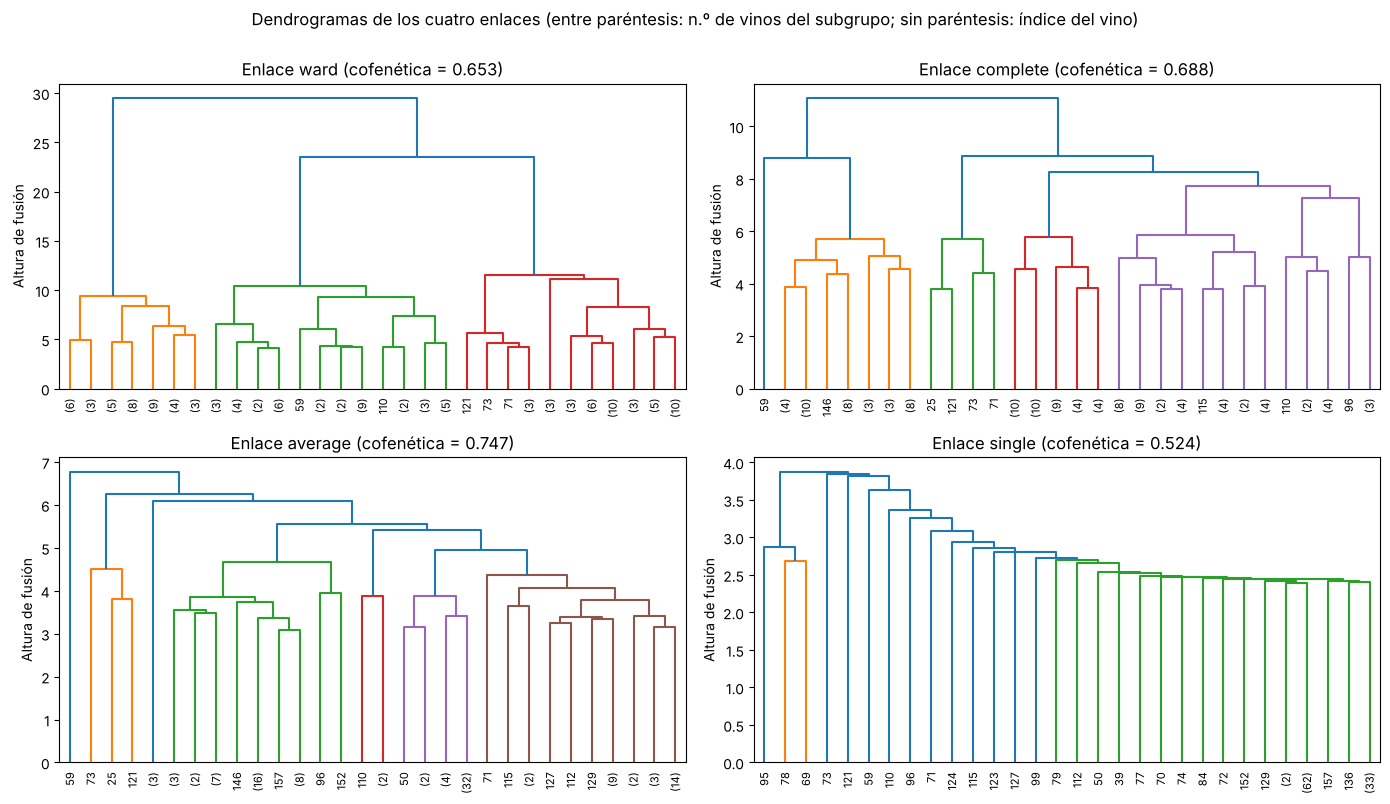

In [24]:
# Comparación visual de los cuatro árboles (truncados a las últimas 30 fusiones)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, enlace in zip(axes.ravel(), ENLACES):
    dendrogram(Z[enlace], truncate_mode='lastp', p=30, ax=ax, leaf_rotation=90,
               leaf_font_size=8, show_leaf_counts=True, labels=X_tr.index.to_numpy())
    ax.set_title(f'Enlace {enlace} (cofenética = {indicadores_m2.loc[enlace, "Cofenética"]})')
    ax.set_ylabel('Altura de fusión')
plt.suptitle('Dendrogramas de los cuatro enlaces (entre paréntesis: n.º de vinos del subgrupo; sin paréntesis: índice del vino)', y=1.0)
plt.tight_layout(); plt.show()

In [25]:
Z_opt = Z[enlace_opt]
h = Z_opt[:, 2]                      # alturas de fusión, ordenadas de menor a mayor
n_tr = len(Xs_tr)
saltos = pd.DataFrame({'k': range(2, 11)})
saltos['altura inferior'] = [h[-k] for k in saltos['k']]          # última fusión que se mantiene
saltos['altura superior'] = [h[-(k - 1)] for k in saltos['k']]    # primera fusión que se deshace
saltos['salto'] = saltos['altura superior'] - saltos['altura inferior']
siluetas_h, tam_min_h = [], []
for k in saltos['k']:
    l = fcluster(Z_opt, t=k, criterion='maxclust')
    siluetas_h.append(silhouette_score(Xs_tr, l)); tam_min_h.append(np.bincount(l)[1:].min())
saltos['silueta train'] = siluetas_h
saltos['grupo más pequeño'] = tam_min_h
saltos[f'cumple ≥ {TAM_MIN}'] = saltos['grupo más pequeño'] >= TAM_MIN
display(saltos.round(3).set_index('k'))

k_opt = int(saltos.loc[saltos['salto'].idxmax(), 'k'])
mejor_sil = saltos[saltos[f'cumple ≥ {TAM_MIN}']].sort_values('silueta train', ascending=False).iloc[0]
print('k sugerido por el mayor salto de altura:', k_opt)
print('k con mayor silueta entre los que cumplen la regla de tamaño:', int(mejor_sil['k']))

,altura inferior,altura superior,salto,silueta train,grupo más pequeño,cumple ≥ 13
k,,,,,,
2,23.487,29.485,5.998,0.259,38,True
3,11.516,23.487,11.971,0.275,38,True
4,11.153,11.516,0.363,0.262,6,False
5,10.435,11.153,0.718,0.279,3,False
6,9.375,10.435,1.060,0.247,3,False
7,9.281,9.375,0.094,0.207,3,False
8,8.404,9.281,0.877,0.204,3,False
9,8.276,8.404,0.128,0.202,3,False
10,7.354,8.276,0.921,0.153,3,False


k sugerido por el mayor salto de altura: 3
k con mayor silueta entre los que cumplen la regla de tamaño: 3


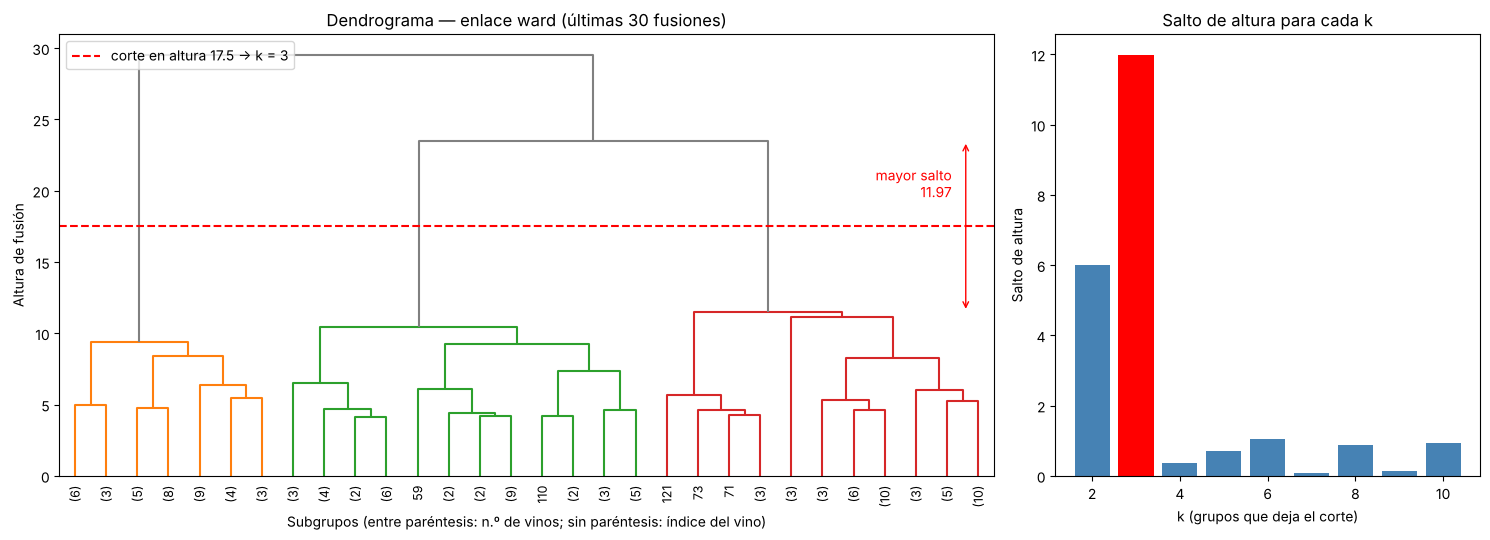

In [26]:
fila_k = saltos.set_index('k').loc[k_opt]
corte = (fila_k['altura inferior'] + fila_k['altura superior']) / 2
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})
dendrogram(Z_opt, truncate_mode='lastp', p=30, color_threshold=corte, ax=ax[0], labels=X_tr.index.to_numpy(),
           leaf_rotation=90, leaf_font_size=9, show_leaf_counts=True, above_threshold_color='grey')
ax[0].axhline(corte, color='red', ls='--', label=f'corte en altura {corte:.1f} -> k = {k_opt}')
ax[0].annotate('', xy=(0.97, fila_k['altura superior']), xytext=(0.97, fila_k['altura inferior']),
               xycoords=('axes fraction', 'data'), arrowprops=dict(arrowstyle='<->', color='red'))
ax[0].text(0.955, (corte + fila_k['altura superior']) / 2, f'mayor salto\n{fila_k["salto"]:.2f}',
           transform=ax[0].get_yaxis_transform(), ha='right', va='center', color='red')
ax[0].set_title(f'Dendrograma — enlace {enlace_opt} (últimas 30 fusiones)')
ax[0].set_xlabel('Subgrupos (entre paréntesis: n.º de vinos; sin paréntesis: índice del vino)'); ax[0].set_ylabel('Altura de fusión')
ax[0].legend(loc='upper left')
ax[1].bar(saltos['k'], saltos['salto'], color=['red' if k == k_opt else 'steelblue' for k in saltos['k']])
ax[1].set_xlabel('k (grupos que deja el corte)'); ax[1].set_ylabel('Salto de altura')
ax[1].set_title('Salto de altura para cada k')
plt.tight_layout(); plt.show()

**Elección de k = 3.**

- **Dendrograma:** la fusión que pasa de 3 a 2 grupos ocurre a una altura de 23,49, cuando la anterior ocurrió a 11,52. Ese **salto de 11,97** es el mayor del árbol y duplica al siguiente (5,99, de 2 a 1 grupo). En las fusiones por debajo de 11,5 los saltos son menores que 1,1. Cortar a cualquier altura entre 11,52 y 23,49 (línea roja en 17,5) deja **3 grupos**, y esa franja es la zona más «larga» y estable del árbol.
- **Silueta:** con Ward, la silueta de entrenamiento es 0,259 (k = 2), 0,275 (k = 3), 0,262 (k = 4) y 0,279 (k = 5). El máximo nominal está en k = 5, pero solo supera a k = 3 en 0,004, y lo logra separando dos «grupos» de 6 y 3 vinos, por debajo del mínimo de 13. Entre los cortes que cumplen la regla de tamaño, la mejor silueta es la de **k = 3**.

Los dos criterios coinciden con el codo y la silueta de K-Means: **k = 3**.

## B.6 Modelo final: entrenamiento, asignación de la prueba y métricas

In [27]:
lab_tr_h = fcluster(Z_opt, t=k_opt, criterion='maxclust') - 1

# Renumerar los grupos para alinearlos con K-Means (solo cambia los nombres, no la partición).
# Se usa la tabla de coincidencias entre las DOS particiones no supervisadas; el cultivar no interviene.
ct = pd.crosstab(lab_tr, lab_tr_h)
filas_a, cols_a = linear_sum_assignment(-ct.values)
mapa = {ct.columns[c]: ct.index[r] for r, c in zip(filas_a, cols_a)}
lab_tr_h = np.array([mapa[g] for g in lab_tr_h])
print('Renumeración aplicada (jerárquico -> K-Means):', {int(k): int(v) for k, v in mapa.items()})
print('Tamaño de cada grupo:', np.bincount(lab_tr_h))

# Comprobación: la implementación de scikit-learn da la misma partición
ag = AgglomerativeClustering(n_clusters=k_opt, linkage=enlace_opt).fit(Xs_tr)
print('ARI scipy vs. AgglomerativeClustering:', adjusted_rand_score(lab_tr_h, ag.labels_))

# Asignación de la prueba: el jerárquico no tiene predict() -> k-NN (k = 5)
knn_h = KNeighborsClassifier(n_neighbors=5).fit(Xs_tr, lab_tr_h)
lab_te_h = knn_h.predict(Xs_te)
print('Tamaños en la prueba:', np.bincount(lab_te_h))
print('\nEntrenamiento:', metricas(Xs_tr, lab_tr_h))
print('Prueba       :', metricas(Xs_te, lab_te_h))
print('\nARI prueba vs. cultivar:', round(adjusted_rand_score(y_te_ref, lab_te_h), 3))
print('NMI prueba vs. cultivar:', round(normalized_mutual_info_score(y_te_ref, lab_te_h), 3))
print(pd.crosstab(y_te_ref, lab_te_h, rownames=['cultivar'], colnames=['grupo jerárquico']))

Renumeración aplicada (jerárquico -> K-Means): {2: 0, 1: 1, 0: 2}
Tamaño de cada grupo: [46 40 38]
ARI scipy vs. AgglomerativeClustering: 1.0
Tamaños en la prueba: [20 18 16]

Entrenamiento: {'silueta': 0.275, 'davies_bouldin': 1.406, 'calinski_harabasz': 47.7}
Prueba       : {'silueta': 0.286, 'davies_bouldin': 1.282, 'calinski_harabasz': 22.7}

ARI prueba vs. cultivar: 0.836
NMI prueba vs. cultivar: 0.826
grupo jerárquico   0   1   2
cultivar                    
0                 19   0   0
1                  1  18   2
2                  0   0  14


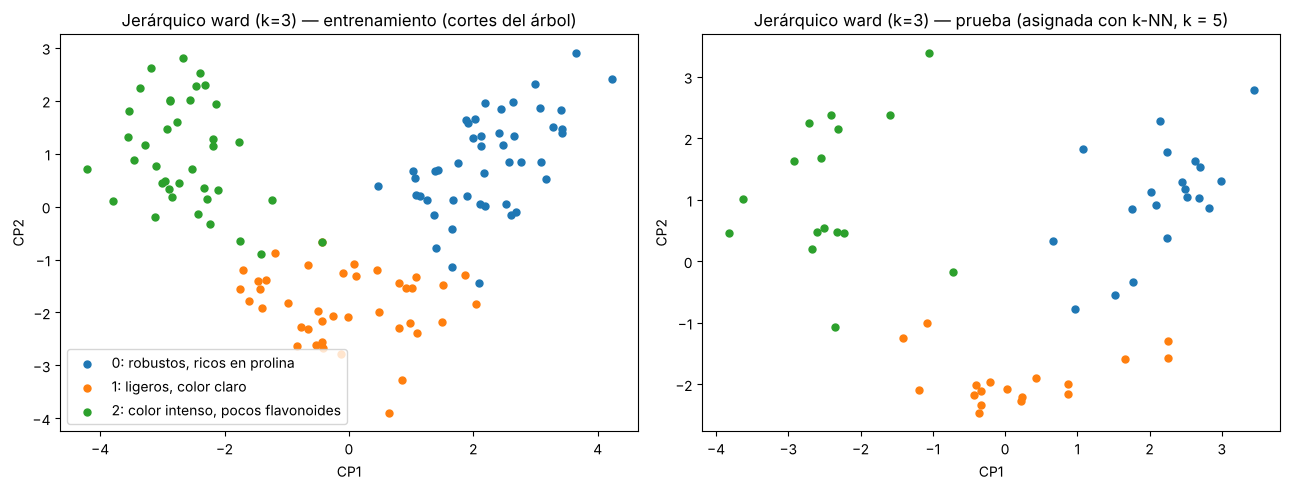

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, P, lab, titulo in [(ax[0], P_tr, lab_tr_h, 'entrenamiento (cortes del árbol)'),
                          (ax[1], P_te, lab_te_h, 'prueba (asignada con k-NN, k = 5)')]:
    for c in range(k_opt):
        a.scatter(P[lab == c, 0], P[lab == c, 1], s=25, label=nombres_km[c])
    a.set_xlabel('CP1'); a.set_ylabel('CP2'); a.set_title(f'Jerárquico {enlace_opt} (k={k_opt}) — {titulo}')
ax[0].legend(); plt.tight_layout(); plt.show()

**Resultados del Modelo 2.** El árbol de Ward cortado en 3 grupos tiene tamaños 46 / 40 / 38 en entrenamiento. La implementación de scipy y `AgglomerativeClustering` dan exactamente la misma partición (ARI = 1). En entrenamiento: silueta 0,275, Davies-Bouldin 1,406 y Calinski-Harabasz 47,7, valores casi idénticos a los de K-Means (0,281 / 1,410 / 48,7). En la prueba: silueta 0,286 y Davies-Bouldin 1,282, de nuevo similares a los de entrenamiento, así que la estructura generaliza. Frente al cultivar, **ARI = 0,836** y **NMI = 0,826**: de los 54 vinos de prueba, 3 del cultivar 1 quedan en otro grupo (1 en el grupo 0 y 2 en el grupo 2).

## B.7 Interpretación: perfil medio de cada grupo frente a los centroides de K-Means

In [29]:
perfil_h = X_tr.groupby(lab_tr_h).mean()
comparacion = pd.concat({f'G{c}': pd.DataFrame({'K-Means': cent.loc[c], 'Jerárquico': perfil_h.loc[c],
                                               'Diferencia': perfil_h.loc[c] - cent.loc[c]})
                         for c in range(k_opt)}, axis=1).round(2)
tam = pd.DataFrame([[np.sum(lab_tr == c), np.sum(lab_tr_h == c), np.sum(lab_tr_h == c) - np.sum(lab_tr == c)]
                    for c in range(k_opt)], index=[f'G{c}' for c in range(k_opt)],
                   columns=['K-Means', 'Jerárquico', 'Diferencia']).stack()
comparacion.loc['n (vinos)'] = tam.values
display(comparacion)
print('Coincidencia de asignaciones en entrenamiento (filas: K-Means, columnas: jerárquico):')
print(pd.crosstab(lab_tr, lab_tr_h, rownames=['K-Means'], colnames=['jerárquico']))

G0                            G1                            G2                      
                              K-Means Jerárquico Diferencia K-Means Jerárquico Diferencia K-Means Jerárquico Diferencia
alcohol                         13.65      13.60      -0.06   12.21      12.17      -0.04   13.08      13.03      -0.05
malic_acid                       1.98       1.93      -0.05    2.04       2.10       0.07    3.36       3.29      -0.08
ash                              2.46       2.44      -0.02    2.24       2.23      -0.00    2.41       2.42       0.00
alcalinity_of_ash               17.38      17.48       0.10   20.22      20.28       0.07   21.13      21.12      -0.01
magnesium                      110.00     110.93       0.93   93.40      89.82      -3.57   99.33     100.34       1.01
total_phenols                    2.86       2.82      -0.04    2.21       2.25       0.04    1.65       1.63      -0.02
flavanoids                       3.01       2.94      -0.07    2.00       2.06       0.05    0.81       0.82       0.01
nonflavanoid_phenols             0.30       0.30      -0.00    0.35       0.37       0.01    0.45       0.44      -0.01
proanthocyanins                  1.95       1.98       0.03    1.66       1.61      -0.05    1.09       1.11       0.02
color_intensity                  5.34       5.21      -0.14    2.93       2.91      -0.01    7.09       6.86      -0.23
hue                              1.07       1.08       0.01    1.06       1.05      -0.01    0.70       0.71       0.01
od280/od315_of_diluted_wines     3.17       3.15      -0.02    2.82       2.86       0.04    1.65       1.67       0.02
proline                       1071.84    1042.76     -29.08  510.38     489.85     -20.53  621.25     627.89       6.64
n (vinos)                       43.00      46.00       3.00   45.00      40.00      -5.00   36.00      38.00       2.00

Coincidencia de asignaciones en entrenamiento (filas: K-Means, columnas: jerárquico):
jerárquico   0   1   2
K-Means               
0           43   0   0
1            3  40   2
2            0   0  36


**Interpretación.** Los tres grupos del jerárquico son **los mismos tres perfiles** que encontró K-Means, y conservan sus nombres:

- **G0 — vinos robustos, ricos en prolina y fenoles:** alcohol 13,60, prolina 1042,8, flavonoides 2,94 (K-Means: 13,65 / 1071,8 / 3,01).
- **G1 — vinos ligeros, de color claro:** alcohol 12,17, intensidad de color 2,91, prolina 489,9 (K-Means: 12,21 / 2,93 / 510,4).
- **G2 — vinos de color intenso, pobres en flavonoides:** flavonoides 0,82, intensidad de color 6,86, ácido málico 3,29 (K-Means: 0,81 / 7,09 / 3,36).

Las diferencias son de unos pocos vinos de frontera: 5 de los 124 cambian de grupo. Ward pasa al grupo G0 tres vinos que K-Means consideraba «ligeros» y al G2 otros dos. Por eso G0 y G2 crecen (46 y 38 frente a 43 y 36) y sus medias se acercan un poco a las del grupo ligero (prolina de G0 −29, intensidad de color de G2 −0,23). Los dos métodos, con criterios distintos (minimizar la inercia frente a fusionar grupos con el menor aumento de varianza), llegan a la misma estructura química. Es una señal de que los grupos son reales.

# Parte C — Comparación de modelos y análisis crítico

## 7.1 Tabla comparativa

Para la **estabilidad** se usan dos pruebas. Frente a las **semillas**, el jerárquico no tiene componente aleatoria; se comprueba que tampoco depende del **orden** de los vinos. Frente a los **datos**, cada modelo se reentrena 20 veces con submuestras del 80 % del entrenamiento y se mide el ARI entre sus asignaciones de la prueba y las del modelo completo. El **tiempo** es el promedio de 20 ejecuciones medidas con `time.time()`.

In [30]:
def tiempo_medio_ms(fn, rep=20):
    ts = []
    for _ in range(rep):
        t0 = time.time(); fn(); ts.append(time.time() - t0)
    return np.mean(ts) * 1000

t_km = tiempo_medio_ms(lambda: KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42).fit(Xs_tr))
t_h = tiempo_medio_ms(lambda: fcluster(linkage(Xs_tr, method=enlace_opt), t=k_opt, criterion='maxclust'))
t_knn = tiempo_medio_ms(lambda: KNeighborsClassifier(n_neighbors=5).fit(Xs_tr, lab_tr_h).predict(Xs_te))
print(f'Tiempo K-Means (n_init=10): {t_km:.2f} ms | árbol {enlace_opt} + corte: {t_h:.2f} ms | k-NN para la prueba: {t_knn:.2f} ms')

# Estabilidad del jerárquico frente al orden de los datos (equivalente a las "semillas")
ari_orden = []
for s in range(10):
    p = np.random.RandomState(s).permutation(len(Xs_tr))
    l_p = np.empty(len(Xs_tr), dtype=int)
    l_p[p] = fcluster(linkage(Xs_tr[p], method=enlace_opt), t=k_opt, criterion='maxclust')
    ari_orden.append(adjusted_rand_score(lab_tr_h, l_p))
print('Jerárquico, ARI frente a 10 reordenamientos de los datos:', np.round(ari_orden, 3))

# Estabilidad frente a los datos: 20 submuestras del 80 % del entrenamiento
rng = np.random.RandomState(42)
est_km, est_h = [], []
for _ in range(20):
    idx = rng.choice(len(Xs_tr), size=int(0.8 * len(Xs_tr)), replace=False)
    S = Xs_tr[idx]
    est_km.append(adjusted_rand_score(lab_te, KMeans(3, n_init=10, random_state=42).fit(S).predict(Xs_te)))
    l_s = fcluster(linkage(S, method=enlace_opt), t=k_opt, criterion='maxclust')
    est_h.append(adjusted_rand_score(lab_te_h, KNeighborsClassifier(n_neighbors=5).fit(S, l_s).predict(Xs_te)))
print(f'Submuestras 80 % -> K-Means: ARI medio {np.mean(est_km):.3f} (mín. {np.min(est_km):.3f}) | '
      f'jerárquico: ARI medio {np.mean(est_h):.3f} (mín. {np.min(est_h):.3f})')

# Consistencia (fuerza de predicción): agrupar la prueba por separado
cons_km = adjusted_rand_score(lab_te, km_te.labels_)
cons_h = adjusted_rand_score(lab_te_h, fcluster(linkage(Xs_te, method=enlace_opt), t=k_opt, criterion='maxclust'))
print(f'Consistencia -> K-Means: {cons_km:.3f} | jerárquico: {cons_h:.3f}')

Tiempo K-Means (n_init=10): 6.82 ms | árbol ward + corte: 0.73 ms | k-NN para la prueba: 2.09 ms
Jerárquico, ARI frente a 10 reordenamientos de los datos: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Submuestras 80 % -> K-Means: ARI medio 0.983 (mín. 0.940) | jerárquico: ARI medio 0.917 (mín. 0.809)
Consistencia -> K-Means: 0.884 | jerárquico: 0.783


In [31]:
m_km_tr, m_km_te = metricas(Xs_tr, lab_tr), metricas(Xs_te, lab_te)
m_h_tr, m_h_te = metricas(Xs_tr, lab_tr_h), metricas(Xs_te, lab_te_h)
f3 = lambda v: f'{v:.3f}'
tabla_comp = pd.DataFrame({
    'K-Means (k = 3)': [
        f"{f3(m_km_tr['silueta'])} / {f3(m_km_te['silueta'])}",
        f3(m_km_te['davies_bouldin']),
        f"{f3(adjusted_rand_score(y_te_ref, lab_te))} / {f3(normalized_mutual_info_score(y_te_ref, lab_te))}",
        f'Semillas: ARI {np.mean(aris):.3f} · submuestras 80 %: {np.mean(est_km):.3f} (mín. {np.min(est_km):.3f}) · consistencia {cons_km:.3f}',
        f'{t_km:.2f} ms (n_init = 10)',
        'Sí, antes de entrenar',
        'Sí: centroide más cercano',
        'Centroides = perfil medio de cada grupo'],
    f'Jerárquico (enlace: {enlace_opt})': [
        f"{f3(m_h_tr['silueta'])} / {f3(m_h_te['silueta'])}",
        f3(m_h_te['davies_bouldin']),
        f"{f3(adjusted_rand_score(y_te_ref, lab_te_h))} / {f3(normalized_mutual_info_score(y_te_ref, lab_te_h))}",
        f'Determinista (orden de datos: ARI {np.mean(ari_orden):.3f}) · submuestras 80 %: {np.mean(est_h):.3f} (mín. {np.min(est_h):.3f}) · consistencia {cons_h:.3f}',
        f'{t_h:.2f} ms (+ {t_knn:.2f} ms del k-NN)',
        'No para construir el árbol; sí para cortarlo (se cambia sin reentrenar)',
        'No: necesita un clasificador auxiliar (k-NN, k = 5)',
        'Dendrograma (jerarquía y alturas) + perfiles medios'],
}, index=['Silueta (train / test)', 'Davies-Bouldin (test)', 'ARI / NMI vs. cultivar (test)',
          'Estabilidad (semillas o datos)', 'Tiempo de entrenamiento (time.time())',
          '¿Requiere fijar k antes?', '¿Asigna datos nuevos (predict)?', 'Interpretabilidad'])
tabla_comp

,K-Means (k = 3),Jerárquico (enlace: ward)
Silueta (train / test),0.281 / 0.296,0.275 / 0.286
Davies-Bouldin (test),1.265,1.282
ARI / NMI vs. cultivar (test),0.946 / 0.935,0.836 / 0.826
Estabilidad (semillas o datos),Semillas: ARI 1.000 · submuestras 80 %: 0.983 ...,Determinista (orden de datos: ARI 1.000) · sub...
Tiempo de entrenamiento (time.time()),6.82 ms (n_init = 10),0.73 ms (+ 2.09 ms del k-NN)
¿Requiere fijar k antes?,"Sí, antes de entrenar",No para construir el árbol; sí para cortarlo (...
¿Asigna datos nuevos (predict)?,Sí: centroide más cercano,"No: necesita un clasificador auxiliar (k-NN, k..."
Interpretabilidad,Centroides = perfil medio de cada grupo,Dendrograma (jerarquía y alturas) + perfiles m...


## 7.2 Preguntas de análisis

In [32]:
print('ARI entre K-Means y jerárquico -> prueba:', round(adjusted_rand_score(lab_te, lab_te_h), 3),
      '| entrenamiento:', round(adjusted_rand_score(lab_tr, lab_tr_h), 3))
print(pd.crosstab(lab_te, lab_te_h, rownames=['K-Means'], colnames=['jerárquico']))

# ¿Qué vinos de prueba se asignan distinto y qué tan "de frontera" son?
d_cent = np.sort(kmeans.transform(Xs_te), axis=1)
margen = d_cent[:, 1] - d_cent[:, 0]           # distancia al 2.º centroide menos distancia al 1.º
dif = lab_te != lab_te_h
display(pd.DataFrame({'K-Means': lab_te[dif], 'Jerárquico': lab_te_h[dif],
                      'Cultivar (verificación)': y_te_ref.values[dif],
                      'Margen entre centroides': margen[dif].round(2)}, index=X_te.index[dif]))
print(f'Margen medio de los 54 vinos de prueba: {margen.mean():.2f} | percentil 10: {np.percentile(margen, 10):.2f}')

ARI entre K-Means y jerárquico -> prueba: 0.887 | entrenamiento: 0.879
jerárquico   0   1   2
K-Means               
0           19   0   0
1            1  18   1
2            0   0  15


,K-Means,Jerárquico,Cultivar (verificación),Margen entre centroides
65,1,0,1,0.54
68,1,2,1,0.18


Margen medio de los 54 vinos de prueba: 1.88 | percentil 10: 0.38


**1. ¿Qué modelo obtuvo mejores métricas internas y externas en la prueba? ¿La diferencia es relevante o marginal?**

K-Means es mejor en todas: silueta 0,296 frente a 0,286, Davies-Bouldin 1,265 frente a 1,282, ARI 0,946 frente a 0,836 y NMI 0,935 frente a 0,826.

- En las **métricas internas la diferencia es marginal**: 0,010 de silueta, un 3 %. Ambos modelos describen la misma estructura con la misma calidad, y en entrenamiento sus métricas son casi idénticas (0,281 / 1,410 / 48,7 frente a 0,275 / 1,406 / 47,7).
- En las **externas parece mayor** (0,11 de ARI), pero en 54 vinos equivale a solo **2 vinos más** mal ubicados: 3 frente a 1. Además, esos 2 vinos no se deben al árbol de Ward sino al paso de asignación. Con el centroide más cercano en lugar del k-NN (Experimento 4), el jerárquico produce exactamente la misma partición de prueba que K-Means.

Conclusión: la diferencia es **marginal** y se explica por la estrategia de asignación, no por la calidad de los grupos.

**2. ¿Qué tan parecidas son las particiones de ambos modelos?**

El ARI entre K-Means y el jerárquico es **0,887 en la prueba** y 0,879 en el entrenamiento. Es un acuerdo muy alto (1 = particiones idénticas, 0 = coincidencia al azar; Hubert & Arabie, 1985): coinciden en 52 de los 54 vinos de prueba y en 119 de los 124 de entrenamiento. Los dos vinos de prueba que difieren (65 y 68) son **vinos de frontera**. Su distancia al segundo centroide de K-Means supera a la del primero en solo 0,54 y 0,18 unidades, cuando el margen medio de la prueba es 1,88; el vino 68 está entre el 10 % más ambiguo. Los dos modelos coinciden en el núcleo de cada grupo y solo discrepan en la zona de contacto del grupo de vinos ligeros con los otros dos.

**3. ¿Qué información aporta el dendrograma que K-Means no puede dar?**

- **La jerarquía completa**, es decir, el orden en que se forman los grupos. El primer corte (k = 2) separa los vinos de color intenso y pobres en flavonoides del resto; después, ese resto se divide en robustos y ligeros. K-Means entrega una partición plana e independiente para cada k (Experimento 2).
- **Las alturas de fusión**, que miden cuán distintos son los grupos que se unen. El salto de 11,97 justifica k = 3 a la vista, sin probar varios modelos.
- **Todos los k a la vez**: cambiar k es mover la línea de corte, no reentrenar.
- **Los atípicos como ramas tardías**: por ejemplo, los vinos 69, 78 y 95, con magnesio extremo, forman una rama propia.

**4. ¿Por qué el jerárquico necesita un paso extra para asignar datos nuevos? ¿Qué consecuencias tiene en producción?**

El jerárquico no aprende parámetros aplicables a un punto nuevo. Su «modelo» es el árbol construido con los puntos de entrenamiento, y las etiquetas salen de cortarlo. Un vino nuevo no tiene lugar en ese árbol. Para incluirlo habría que reconstruir todo el árbol, con costo O(n²) en memoria, y eso podría cambiar la numeración e incluso los grupos ya existentes. Por eso se entrena un clasificador auxiliar (k-NN o centroides) con las etiquetas del corte. En producción esto implica:

- **Dos modelos que mantener y versionar** (árbol y clasificador), y la calidad final depende del clasificador. En Wine, el k-NN ubica mal 2 vinos que el centroide sí acierta.
- **La estructura no se actualiza sola.** Si llega un tipo de vino nuevo, se asignará a un grupo existente sin crear uno nuevo, y habrá que reconstruir el árbol periódicamente.
- **Mayor costo por predicción.** El k-NN guarda todo el entrenamiento y calcula distancias contra todos los puntos. K-Means compara cada vino nuevo solo con 3 centroides.

## 7.3 ¿Cuándo funcionaría mejor el Clustering Jerárquico? ¿Qué faltó?

Para sostener la conclusión se realizan cinco experimentos: formas no esféricas, jerarquía natural, elección de k sin conocerlo, preprocesamiento y asignación de la prueba, y escala.

### Experimento 1 — Formas no esféricas (`make_moons`)

Las etiquetas de luna se usan solo para verificar (ARI). Las dos variables ya están en escalas similares, así que no se estandarizan.

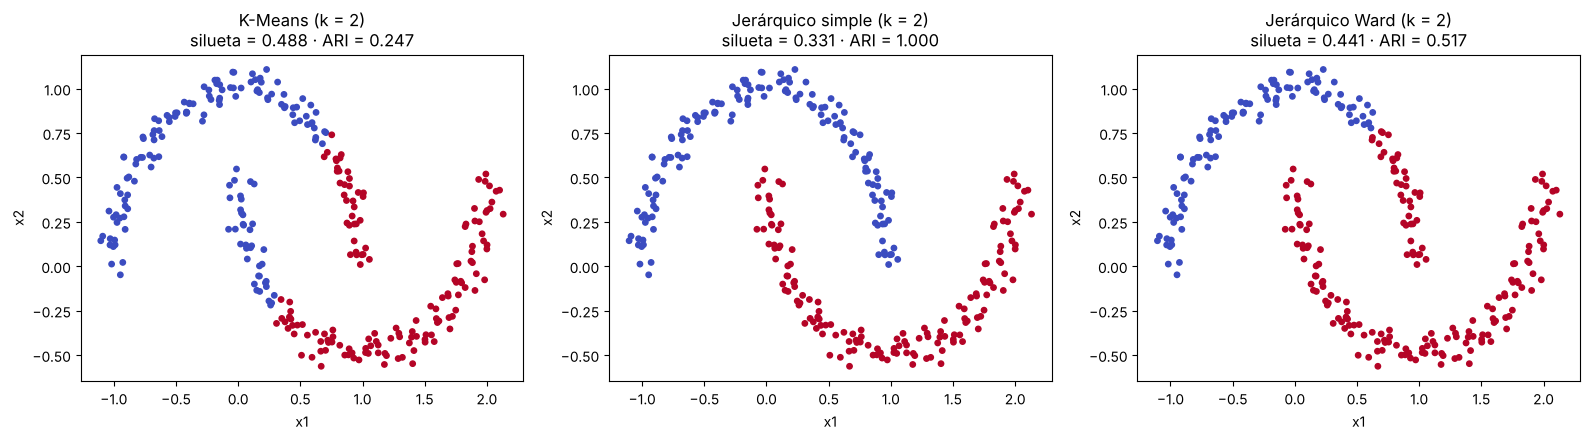

,Tamaños,Silueta,ARI vs. luna
Modelo,,,
K-Means (k = 2),151 / 149,0.488,0.247
Jerárquico simple (k = 2),150 / 150,0.331,1.000
Jerárquico Ward (k = 2),108 / 192,0.441,0.517


In [33]:
from sklearn.datasets import make_moons
X_lunas, y_lunas = make_moons(n_samples=300, noise=0.05, random_state=42)
modelos_lunas = {
    'K-Means (k = 2)': KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_lunas),
    'Jerárquico simple (k = 2)': fcluster(linkage(X_lunas, method='single'), t=2, criterion='maxclust') - 1,
    'Jerárquico Ward (k = 2)': fcluster(linkage(X_lunas, method='ward'), t=2, criterion='maxclust') - 1}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
filas_lunas = []
for a, (nombre, lab) in zip(ax, modelos_lunas.items()):
    sil, ari = silhouette_score(X_lunas, lab), adjusted_rand_score(y_lunas, lab)
    a.scatter(X_lunas[:, 0], X_lunas[:, 1], c=lab, cmap='coolwarm', s=15)
    a.set_title(f'{nombre}\nsilueta = {sil:.3f} · ARI = {ari:.3f}'); a.set_xlabel('x1'); a.set_ylabel('x2')
    filas_lunas.append({'Modelo': nombre, 'Tamaños': ' / '.join(map(str, np.bincount(lab))),
                        'Silueta': round(sil, 3), 'ARI vs. luna': round(ari, 3)})
plt.tight_layout(); plt.show()
pd.DataFrame(filas_lunas).set_index('Modelo')

**Resultado.** K-Means con k = 2 corta las lunas con una recta (ARI 0,247) y cada grupo mezcla mitades de las dos lunas, porque supone grupos convexos alrededor de un centroide. El **enlace simple** las separa **perfectamente** (ARI 1,000; 150 / 150): une cada punto con su vecino más cercano y sigue la forma de cada luna como una cadena. Funciona porque el ruido es bajo (0,05) y no hay puntos que hagan de «puente» entre las lunas. Ward, que también busca grupos compactos, falla de forma parecida a K-Means (ARI 0,517).

Hay un detalle clave: la **silueta prefiere la solución equivocada** de K-Means (0,488) sobre la correcta del enlace simple (0,331), porque también premia los grupos convexos y compactos. Con formas no esféricas, las métricas internas basadas en distancias pueden elegir el modelo incorrecto.

### Experimento 2 — Jerarquía natural: cortes en k = 2, 3 y 6

Se mide el **anidamiento**: el porcentaje de vinos cuyo subgrupo del corte fino cae entero dentro de un solo grupo del corte grueso (100 % = jerarquía perfecta).

In [34]:
def anidamiento(grueso, fino):
    ct = pd.crosstab(fino, grueso)
    puros = (ct > 0).sum(axis=1) == 1
    return 100 * ct[puros].values.sum() / ct.values.sum(), f'{int(puros.sum())} de {len(ct)}'

cortes_h = {k: fcluster(Z_opt, t=k, criterion='maxclust') for k in (2, 3, 6)}
cortes_km = {k: KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs_tr) for k in (2, 3, 6)}
filas_anid = []
for nombre, cortes in [(f'Jerárquico {enlace_opt}', cortes_h), ('K-Means', cortes_km)]:
    for grueso, fino in [(2, 3), (3, 6)]:
        pct, puros = anidamiento(cortes[grueso], cortes[fino])
        filas_anid.append({'Modelo': nombre, 'Anidamiento': f'k={fino} dentro de k={grueso}',
                           'Vinos anidados (%)': round(pct, 1), 'Subgrupos puros': puros})
display(pd.DataFrame(filas_anid).set_index(['Modelo', 'Anidamiento']))

print('Jerárquico: k = 3 (filas, con la numeración de B.6) frente a k = 6 (columnas)')
g3 = pd.Series(lab_tr_h, name='k=3 (G)')
print(pd.crosstab(g3, pd.Series(cortes_h[6], name='k=6')))
print('\nJerárquico: k = 2 (filas) frente a k = 3 (columnas)')
print(pd.crosstab(pd.Series(cortes_h[2], name='k=2'), g3))
print('\nK-Means: k = 3 (filas) frente a k = 6 (columnas)')
print(pd.crosstab(pd.Series(cortes_km[3], name='k=3'), pd.Series(cortes_km[6], name='k=6')))

Vinos anidados (%) Subgrupos puros
Modelo          Anidamiento                                          
Jerárquico ward k=3 dentro de k=2               100.0          3 de 3
                k=6 dentro de k=3               100.0          6 de 6
K-Means         k=3 dentro de k=2                63.7          2 de 3
                k=6 dentro de k=3                55.6          2 de 6

Jerárquico: k = 3 (filas, con la numeración de B.6) frente a k = 6 (columnas)
k=6       1   2   3  4  5   6
k=3 (G)                      
0         0   0   0  6  3  37
1         0  15  25  0  0   0
2        38   0   0  0  0   0

Jerárquico: k = 2 (filas) frente a k = 3 (columnas)
k=3 (G)   0   1   2
k=2                
1         0   0  38
2        46  40   0

K-Means: k = 3 (filas) frente a k = 6 (columnas)
k=6  0   1   2   3  4   5
k=3                      
0    1   0  36   0  4   2
1    3  18   0   0  4  20
2    0   3   0  33  0   0


,n,grupo k=3,alcohol,flavanoids,color_intensity,proline,magnesium,alcalinity_of_ash,ash
1,38,2,13.03,0.82,6.86,627.89,100.34,21.12,2.42
2,15,1,12.08,1.89,2.76,492.93,88.33,22.21,2.42
3,25,1,12.23,2.15,3.01,488.00,90.72,19.13,2.12
4,6,0,13.10,3.20,4.19,723.33,115.50,24.82,2.90
5,3,0,12.34,1.80,2.95,801.67,149.67,16.87,1.97
6,37,0,13.78,3.00,5.55,1114.11,107.05,16.34,2.41


Subgrupo 4: vinos [4, 28, 25, 73, 121, 71]
Subgrupo 5: vinos [78, 69, 95]


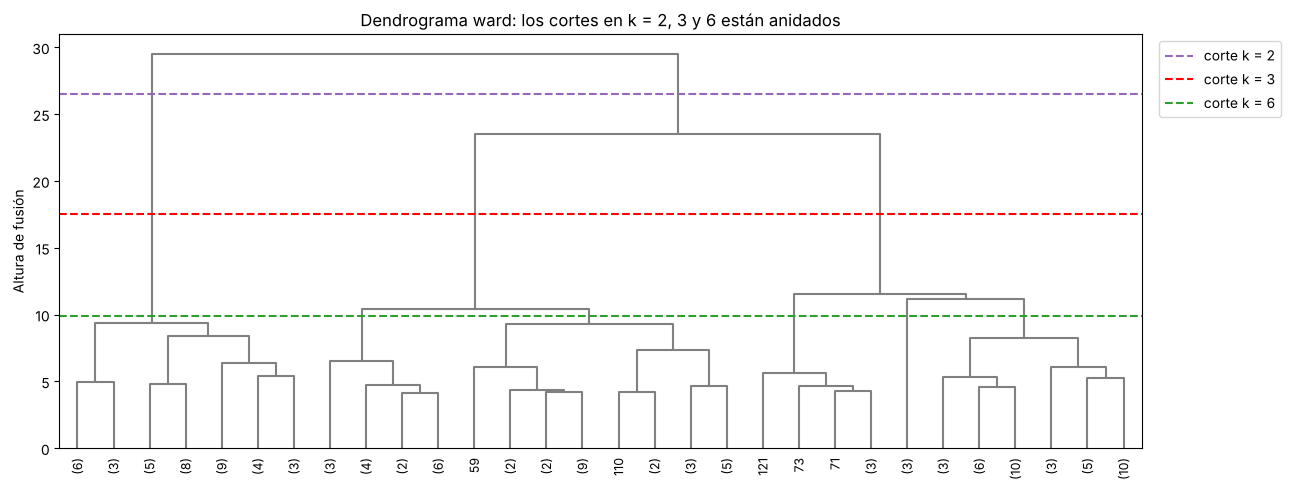

In [35]:
# Perfil de los 6 subgrupos del jerárquico (escala original) y qué vinos forman los más pequeños
vars_clave = ['alcohol', 'flavanoids', 'color_intensity', 'proline', 'magnesium', 'alcalinity_of_ash', 'ash']
perfil6 = X_tr.groupby(cortes_h[6])[vars_clave].mean().round(2)
perfil6.insert(0, 'n', np.bincount(cortes_h[6])[1:])
perfil6.insert(1, 'grupo k=3', [int(pd.Series(lab_tr_h[cortes_h[6] == s]).mode()[0]) for s in perfil6.index])
display(perfil6)
for s in perfil6.index[perfil6['n'] < TAM_MIN]:
    print(f'Subgrupo {s}: vinos', list(X_tr.index[cortes_h[6] == s]))

# Dendrograma con los tres cortes
fig, ax = plt.subplots(figsize=(13, 5))
dendrogram(Z_opt, truncate_mode='lastp', p=30, ax=ax, leaf_rotation=90, leaf_font_size=9,
           color_threshold=0, above_threshold_color='grey', labels=X_tr.index.to_numpy())
for k, col in [(2, 'tab:purple'), (3, 'red'), (6, 'tab:green')]:
    ax.axhline((h[-k] + h[-(k - 1)]) / 2, color=col, ls='--', label=f'corte k = {k}')
ax.set_title(f'Dendrograma {enlace_opt}: los cortes en k = 2, 3 y 6 están anidados')
ax.set_ylabel('Altura de fusión'); ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

**Resultado.** El árbol de Ward forma una **jerarquía perfecta** (100 % de anidamiento):

- **k = 2:** separa los 38 vinos de color intenso y pobres en flavonoides (G2) de los 86 restantes. Es la diferencia química más grande del dataset.
- **k = 3:** esos 86 vinos se dividen en robustos (G0, 46) y ligeros (G1, 40).
- **k = 6:** cada subgrupo cae entero dentro de un grupo de k = 3. G2 queda intacto: es el grupo más homogéneo. G1 se divide en dos subgrupos de 15 y 25 vinos que difieren sobre todo en alcalinidad (22,21 frente a 19,13) y cenizas (2,42 frente a 2,12). G0 se divide en un núcleo de 37 vinos (prolina 1114, alcohol 13,78) y dos ramas pequeñas: 6 vinos con cenizas y alcalinidad altas (4, 28, 25, 73, 121 y 71, tres de ellos atípicos según la regla IQR) y 3 vinos con magnesio extremo (78, 69 y 95, con media 149,7).

Los subgrupos de k = 6 **tienen sentido** dentro de los de k = 3: son matices de un mismo tipo de vino o ramas de vinos atípicos. **K-Means no garantiza esa anidación**: su partición de k = 6 solo respeta el 55,6 % de los vinos (2 de 6 subgrupos puros), y la de k = 3 frente a k = 2, el 63,7 %. Por ejemplo, uno de sus subgrupos de k = 6 mezcla 20 vinos ligeros con 2 robustos. Cada k se recalcula desde cero, así que las particiones no tienen relación entre sí.

### Experimento 3 — Sin conocer k: ¿qué sugiere cada criterio?

In [36]:
caidas = -np.diff(inercias)                    # caída de inercia de k a k+1
k_codo = list(ks)[1 + int(np.argmax(caidas[:-1] - caidas[1:]))]   # máxima curvatura
resumen_k = pd.DataFrame([
    {'Criterio': 'Codo de la inercia (K-Means)', 'k sugerido': k_codo,
     'Evidencia': f'caída {caidas[0]:.1f} (2→3) frente a {caidas[1]:.1f} (3→4)'},
    {'Criterio': 'Silueta máxima (K-Means)', 'k sugerido': list(ks)[int(np.argmax(siluetas))],
     'Evidencia': f'silueta {max(siluetas):.3f}'},
    {'Criterio': 'Mayor salto del dendrograma (Ward)', 'k sugerido': k_opt,
     'Evidencia': f"salto {saltos['salto'].max():.2f}; el siguiente es {saltos['salto'].nlargest(2).iloc[1]:.2f} (k = {int(saltos.loc[saltos['salto'].nlargest(2).index[1], 'k'])})"},
    {'Criterio': 'Silueta máxima (Ward), sin regla de tamaño', 'k sugerido': int(saltos.loc[saltos['silueta train'].idxmax(), 'k']),
     'Evidencia': f"silueta {saltos['silueta train'].max():.3f}, grupo más pequeño = {int(saltos.loc[saltos['silueta train'].idxmax(), 'grupo más pequeño'])} vinos"},
    {'Criterio': f'Silueta máxima (Ward), con regla ≥ {TAM_MIN}', 'k sugerido': int(mejor_sil['k']),
     'Evidencia': f"silueta {mejor_sil['silueta train']:.3f}"},
]).set_index('Criterio')
resumen_k

,k sugerido,Evidencia
Criterio,,
Codo de la inercia (K-Means),3,caída 259.2 (2→3) frente a 84.5 (3→4)
Silueta máxima (K-Means),3,silueta 0.281
Mayor salto del dendrograma (Ward),3,salto 11.97; el siguiente es 6.00 (k = 2)
"Silueta máxima (Ward), sin regla de tamaño",5,"silueta 0.279, grupo más pequeño = 3 vinos"
"Silueta máxima (Ward), con regla ≥ 13",3,silueta 0.275


**Resultado.** Sí: el dendrograma sugiere el **mismo k = 3** que el codo y la silueta de K-Means. Su mayor salto (11,97) duplica al siguiente (6,00, que indicaría k = 2). La única discrepancia aparece al aplicar la silueta al árbol de Ward sin ningún otro criterio: el máximo nominal está en k = 5 (0,279 frente a 0,275), pero se logra separando «grupos» de 6 y 3 vinos atípicos. Con la regla de tamaño mínimo vuelve a k = 3.

**¿Cuál es más fácil de justificar ante un experto?** El dendrograma. Un enólogo puede ver que los tres grupos se forman a poca altura y tardan mucho en unirse, y se le puede explicar qué pasa con cualquier otra elección: «con 2 grupos se juntan robustos y ligeros; con 6 aparecen ramas de vinos con magnesio extremo». El codo y la silueta son números agregados, más difíciles de traducir al dominio, y el codo suele ser ambiguo: aquí, por ejemplo, la caída de 5 a 6 grupos (60,0) es mayor que la de 4 a 5 (52,8). El segundo mayor salto del árbol también informa: la siguiente división natural es k = 2, no k = 4.

### Experimento 4 — Preprocesamiento y estrategia de asignación

**(a) Preprocesamiento.** Se repite el jerárquico (k = 3) con tres enlaces sobre: los datos base; las 5 primeras componentes PCA (81 % de la varianza, ajustadas solo con el entrenamiento); y el entrenamiento sin los 4 vinos anómalos del Paso 9 (59, 69, 95 y 121). Para que las siluetas sean comparables, **siempre se calculan en el espacio estandarizado de 13 variables**.

In [37]:
pca5 = PCA(n_components=5, random_state=42).fit(Xs_tr)
P5_tr, P5_te = pca5.transform(Xs_tr), pca5.transform(Xs_te)
sin_atip = d_tr <= umbral
print('Varianza explicada por 5 CP:', round(pca5.explained_variance_ratio_.sum(), 3),
      '| vinos quitados del entrenamiento:', list(X_tr.index[~sin_atip]))
variantes = {'Base (13 variables)': (Xs_tr, Xs_te, np.ones(len(Xs_tr), dtype=bool)),
             'PCA 5 componentes': (P5_tr, P5_te, np.ones(len(Xs_tr), dtype=bool)),
             'Sin atípicos del Paso 9': (Xs_tr[sin_atip], Xs_te, sin_atip)}
filas_pre = []
for nombre, (A, B, m) in variantes.items():
    for enlace in ['ward', 'complete', 'average']:
        l = fcluster(linkage(A, method=enlace), t=3, criterion='maxclust') - 1
        lt = KNeighborsClassifier(n_neighbors=5).fit(A, l).predict(B)
        mt = metricas_seguras(Xs_te, lt)
        filas_pre.append({'Preprocesamiento': nombre, 'Enlace': enlace,
                          'Tamaños': ' / '.join(map(str, sorted(np.bincount(l), reverse=True))),
                          f'Mín. ≥ {TAM_MIN}': bool(np.bincount(l).min() >= TAM_MIN),
                          'Silueta train (13D)': round(silhouette_score(Xs_tr[m], l), 3),
                          'Silueta test (13D)': mt['silueta'], 'DB test': mt['davies_bouldin'],
                          'ARI test': round(adjusted_rand_score(y_te_ref, lt), 3),
                          'NMI test': round(normalized_mutual_info_score(y_te_ref, lt), 3)})
pd.DataFrame(filas_pre).set_index(['Preprocesamiento', 'Enlace']).fillna('n. d.')

Varianza explicada por 5 CP: 0.812 | vinos quitados del entrenamiento: [69, 95, 59, 121]


Tamaños  Mín. ≥ 13  Silueta train (13D) Silueta test (13D) DB test  ARI test  NMI test
Preprocesamiento        Enlace                                                                                               
Base (13 variables)     ward      46 / 40 / 38       True                0.275              0.286   1.282     0.836     0.826
                        complete   82 / 38 / 4      False                0.226              0.278   1.423     0.432     0.574
                        average    120 / 3 / 1      False                0.159              n. d.   n. d.     0.000     0.000
PCA 5 componentes       ward      45 / 41 / 38       True                0.265              0.277    1.31     0.781     0.760
                        complete  51 / 41 / 32       True                0.265              0.283   1.281     0.880     0.864
                        average    86 / 37 / 1      False                0.242              0.278   1.423     0.432     0.574
Sin atípicos del Paso 9 ward      43 / 42 / 35       True                0.291              0.286   1.282     0.836     0.826
                        complete  43 / 40 / 37       True                0.288              0.286   1.282     0.836     0.826
                        average    77 / 40 / 3      False                0.237               0.28    1.45     0.412     0.543

**(b) Estrategia de asignación de la prueba.** Con el árbol de Ward ya elegido, se compara el k-NN (k = 5) con el centroide más cercano de cada grupo. La elección se basa en las métricas **internas** de prueba; el ARI se mira después.

In [38]:
lab_te_h_cent = NearestCentroid().fit(Xs_tr, lab_tr_h).predict(Xs_te)
asignacion = pd.DataFrame([
    {'Asignación': 'k-NN (k = 5)', **metricas(Xs_te, lab_te_h),
     'ARI test': round(adjusted_rand_score(y_te_ref, lab_te_h), 3),
     'NMI test': round(normalized_mutual_info_score(y_te_ref, lab_te_h), 3)},
    {'Asignación': 'Centroide más cercano', **metricas(Xs_te, lab_te_h_cent),
     'ARI test': round(adjusted_rand_score(y_te_ref, lab_te_h_cent), 3),
     'NMI test': round(normalized_mutual_info_score(y_te_ref, lab_te_h_cent), 3)}]).set_index('Asignación')
display(asignacion)
print('Vinos de prueba en los que difieren las dos estrategias:', list(X_te.index[lab_te_h != lab_te_h_cent]))
print('ARI entre "jerárquico + centroide" y K-Means en la prueba:', round(adjusted_rand_score(lab_te, lab_te_h_cent), 3))

,silueta,davies_bouldin,calinski_harabasz,ARI test,NMI test
Asignación,,,,,
k-NN (k = 5),0.286,1.282,22.7,0.836,0.826
Centroide más cercano,0.296,1.265,23.7,0.946,0.935


Vinos de prueba en los que difieren las dos estrategias: [65, 68]
ARI entre "jerárquico + centroide" y K-Means en la prueba: 1.0


**Resultado (a): preprocesamiento.**

- **Quitar los 4 atípicos** del Paso 9 transforma el enlace **completo**: pasa de 82 / 38 / 4 (un grupo gastado en atípicos) a 43 / 40 / 37, y en la prueba produce las mismas métricas que Ward (silueta 0,286, ARI 0,836). Esto confirma que el enlace completo es **sensible a los atípicos**: como mide la distancia entre los puntos más lejanos, un solo vino extremo aleja a todo su grupo. Ward mejora su silueta de entrenamiento (0,275 → 0,291) y no cambia en la prueba. El promedio sigue aislando 3 vinos (77 / 40 / 3).
- **PCA con 5 componentes** elimina la redundancia del bloque fenólico, y el enlace completo también se equilibra (51 / 41 / 32), con ARI 0,880. Ward, en cambio, empeora levemente (silueta de prueba 0,277, ARI 0,781): descartar el 19 % de la varianza también quita información útil para separar algunos vinos de frontera.
- Ningún preprocesamiento rescata al enlace promedio con k = 3.

**Resultado (b): asignación de la prueba.** Con el **centroide más cercano**, las métricas internas de prueba mejoran (silueta 0,286 → 0,296; Davies-Bouldin 1,282 → 1,265), así que es la estrategia preferible según criterios sin etiquetas. La verificación posterior lo confirma: ARI 0,946 y NMI 0,935, con una partición de prueba **idéntica a la de K-Means** (ARI entre ambas = 1,000). Las dos estrategias solo difieren en los vinos de frontera 65 y 68. El k-NN decide por mayoría entre 5 vecinos y, cerca de la frontera, lo arrastran los vecinos del otro grupo. El centroide, en cambio, es coherente con Ward, que forma grupos compactos alrededor de su media. **Esto es lo que le faltó al Modelo 2:** el árbol era tan bueno como K-Means, y la diferencia estaba en cómo se asignaba la prueba.

### Experimento 5 — Escala: 2 000 y 20 000 puntos sintéticos (`make_blobs`)

Se generan 3 grupos en 13 dimensiones (como Wine) con `cluster_std=4.0`. Los grupos se tocan un poco, así que el grafo de vecinos queda **conexo**. Con grupos totalmente separados, scikit-learn tiene que «unir» componentes sueltas del grafo, un paso costoso que distorsionaría la medición. Se mide el tiempo con `time.time()` y el **pico de memoria** con `tracemalloc` (cuenta la memoria que Python y numpy reservan durante el ajuste; es una cota inferior del consumo real del proceso). La conectividad usa `kneighbors_graph` con 10 vecinos, y el tiempo incluye construir el grafo.

> ⚠️ Con 20 000 puntos, el Ward sin conectividad necesita casi 2 GB de RAM y la celda tarda alrededor de un minuto. Para una ejecución rápida, poner `EJECUTAR_20000 = False`.

In [39]:
import tracemalloc
from sklearn.datasets import make_blobs
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import connected_components

EJECUTAR_20000 = True

def medir(fn):
    tracemalloc.start(); t0 = time.time()
    resultado = fn()
    t = time.time() - t0
    _, pico = tracemalloc.get_traced_memory(); tracemalloc.stop()
    return resultado, t, pico / 2**20

filas_esc = []
for n in ([2000, 20000] if EJECUTAR_20000 else [2000]):
    Xb, yb = make_blobs(n_samples=n, centers=3, n_features=13, cluster_std=4.0, random_state=42)
    print(f'n = {n:>6}: matriz de distancias condensada = n(n-1)/2 · 8 bytes = {n * (n - 1) / 2 * 8 / 2**20:,.0f} MB'
          f' | componentes del grafo k-NN: {connected_components(kneighbors_graph(Xb, n_neighbors=10))[0]}')
    modelos = {
        'K-Means (k = 3)': lambda: KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Xb),
        'Jerárquico Ward': lambda: AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(Xb),
        'Ward + conectividad (10 vecinos)': lambda: AgglomerativeClustering(
            n_clusters=3, linkage='ward',
            connectivity=kneighbors_graph(Xb, n_neighbors=10, include_self=False)).fit_predict(Xb)}
    for nombre, fn in modelos.items():
        lab_b, t, mem = medir(fn)
        filas_esc.append({'n': n, 'Modelo': nombre, 'Tiempo (s)': round(t, 2),
                          'Memoria pico (MB)': round(mem, 1), 'ARI vs. grupos reales': round(adjusted_rand_score(yb, lab_b), 3)})
tabla_esc = pd.DataFrame(filas_esc).set_index(['n', 'Modelo'])
tabla_esc

n =   2000: matriz de distancias condensada = n(n-1)/2 · 8 bytes = 15 MB | componentes del grafo k-NN: 1
n =  20000: matriz de distancias condensada = n(n-1)/2 · 8 bytes = 1,526 MB | componentes del grafo k-NN: 1


Tiempo (s)  Memoria pico (MB)  ARI vs. grupos reales
n     Modelo                                                                                
2000  K-Means (k = 3)                         0.02                0.5                  0.997
      Jerárquico Ward                         0.09               17.2                  0.994
      Ward + conectividad (10 vecinos)        1.52                8.0                  0.994
20000 K-Means (k = 3)                         0.08                4.0                  0.998
      Jerárquico Ward                        17.97             1716.5                  0.994
      Ward + conectividad (10 vecinos)       25.80               93.5                  0.994

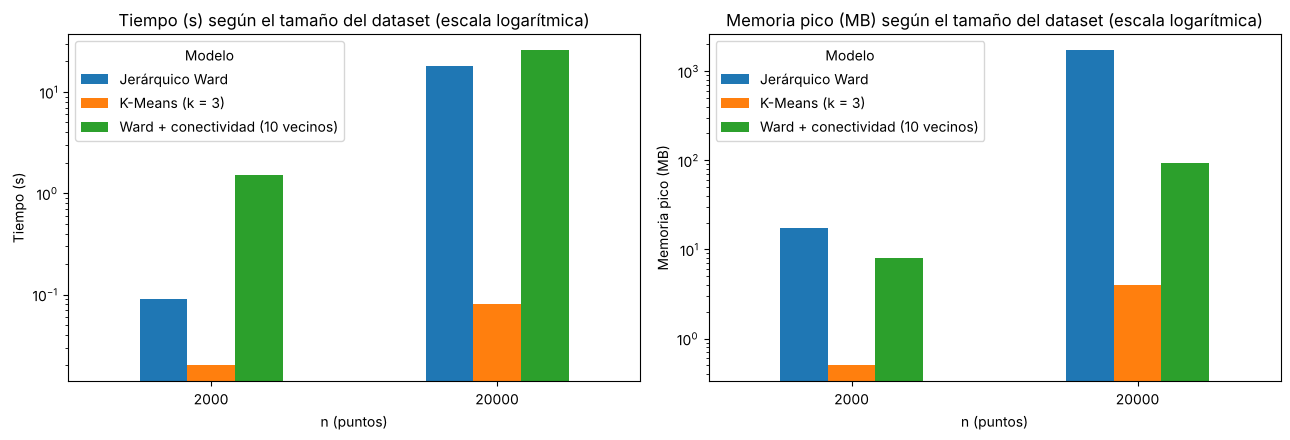

Multiplicador al pasar de 2 000 a 20 000 puntos (x10 datos):
                                  Tiempo (s)  Memoria pico (MB)
Modelo                                                         
K-Means (k = 3)                          4.0                8.0
Jerárquico Ward                        199.7               99.8
Ward + conectividad (10 vecinos)        17.0               11.7


In [40]:
if EJECUTAR_20000:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for a, col in zip(ax, ['Tiempo (s)', 'Memoria pico (MB)']):
        tabla_esc[col].unstack('Modelo').plot(kind='bar', ax=a, logy=True, rot=0)
        a.set_title(f'{col} según el tamaño del dataset (escala logarítmica)'); a.set_xlabel('n (puntos)'); a.set_ylabel(col)
    plt.tight_layout(); plt.show()
    r = tabla_esc.xs(20000) / tabla_esc.xs(2000)
    print('Multiplicador al pasar de 2 000 a 20 000 puntos (x10 datos):')
    print(r[['Tiempo (s)', 'Memoria pico (MB)']].round(1))

**Resultado.** Con 2 000 puntos los tres métodos son rápidos. Al multiplicar los datos por 10:

- **K-Means** escala casi linealmente: con 20 000 puntos tarda menos de 0,1 s y usa unos 4 MB.
- **Ward sin conectividad** pasa de menos de 0,1 s a más de 15 s (más de 150 veces el tiempo) y de 17 MB a unos 1 700 MB: la memoria se multiplica ×100, es decir, crece con **n²**. Coincide con el tamaño de la matriz de distancias condensada (1 526 MB para 20 000 puntos). Con 100 000 puntos esa matriz ocuparía unos 37 GB, algo inviable en un computador personal.
- **Con matriz de conectividad** (`kneighbors_graph`, 10 vecinos), cada punto solo puede fusionarse con sus vecinos. La memoria baja a unos 94 MB (**unas 18 veces menos**) y crece casi linealmente (×12), sin perder calidad (ARI 0,994, igual que sin conectividad). El tiempo, en cambio, no mejora a estos tamaños (≈ 25 s): la versión con conectividad de scikit-learn gestiona las fusiones con una cola de prioridad que es más lenta por operación. Su tiempo crece unas 17 veces, frente a más de 150 veces el del Ward completo, así que con algunas decenas de miles de puntos más previsiblemente también ganaría en tiempo.

*Los tiempos cambian entre ejecuciones y entre computadores; las memorias y las tendencias son estables.*

**¿Ayuda la conectividad?** Sí: convierte un problema imposible por memoria en uno factible, a cambio de un costo fijo mayor. Aun así, el jerárquico sigue siendo el método más caro de los tres. Con datos grandes conviene K-Means (o Mini-Batch K-Means), o construir el árbol sobre una muestra y asignar el resto con centroides.

### Conclusión: ¿cuándo funcionaría mejor el Clustering Jerárquico y qué faltó?

En Wine, los dos modelos descubren la misma estructura: tres tipos de vino (robustos ricos en prolina y fenoles, ligeros de color claro, y de color intenso pobres en flavonoides) que coinciden casi exactamente con los cultivares, sin haberlos usado nunca. K-Means obtuvo métricas de prueba algo mejores (silueta 0,296 frente a 0,286; ARI 0,946 frente a 0,836). Sin embargo, la diferencia es marginal y, como mostró el Experimento 4, no proviene del árbol sino de la asignación con k-NN: con el centroide más cercano, el jerárquico reproduce exactamente la partición de K-Means. En un dataset pequeño, con grupos aproximadamente esféricos y de tamaño similar, **K-Means es la opción más práctica**: predice datos nuevos de forma directa, es estable frente a semillas y submuestras (ARI 1,000 y 0,983) y escala linealmente.

El clustering jerárquico funcionaría mejor en cuatro situaciones, todas respaldadas por los experimentos:

1. **Grupos de forma no esférica.** Con enlace simple separó las lunas a la perfección (ARI 1,000), donde K-Means falló (0,247).
2. **Cuando interesa la jerarquía.** Sus cortes en k = 2, 3 y 6 están 100 % anidados y revelan subtipos con sentido químico. K-Means no garantiza esa coherencia (55,6 %).
3. **Cuando k es desconocido y hay que justificarlo ante expertos.** El dendrograma muestra por qué k = 3 (un salto de 11,97, el doble del siguiente) y qué ocurre con cualquier otro k sin reentrenar.
4. **Para explorar atípicos**, que aparecen como ramas que se unen tarde.

Sus límites también quedaron medidos:

- **Costo O(n²) en memoria:** 1,7 GB con 20 000 puntos. La matriz de conectividad lo reduce unas 18 veces, pero no acelera el cálculo a ese tamaño.
- **El enlace es decisivo:** el promedio, el simple y el completo gastaron grupos en 1 a 4 vinos atípicos. El enlace con mayor cofenética (el promedio) fue el peor, así que la cofenética nunca debe usarse sola.
- **No tiene `predict()`**, lo que obliga a mantener un clasificador auxiliar en producción.

**Qué faltó para que el Modelo 2 rinda mejor:**

- **(a)** Asignar la prueba con el centroide más cercano, coherente con Ward, en lugar del k-NN.
- **(b)** Tratar los atípicos antes de construir el árbol, lo que vuelve útil incluso al enlace completo.
- **(c)** Fijar desde el principio una regla de tamaño mínimo de grupo, para no depender de una sola métrica.
- **(d)** Con más datos, usar conectividad o una muestra para construir el árbol.

El escalado, en cambio, fue correcto y necesario. Sin él, la prolina habría decidido sola los grupos.

# 8. Preguntas teóricas

**1. ¿Por qué es obligatorio escalar las variables antes de K-Means y del clustering jerárquico en este dataset?**

Porque ambos métodos se basan en la distancia euclidiana, que suma las diferencias al cuadrado de todas las variables con el mismo peso. Así, la variable con mayor rango domina la distancia (Géron, 2019; Mueller & Massaron, 2016). En el EDA, la prolina va de 278 a 1680 (desviación 314,91), mientras que el tono va de 0,48 a 1,71 (desviación 0,23): la varianza de la prolina es casi 1,9 millones de veces la del tono, y el magnesio (desviación 14,28) ocupa el segundo lugar. El experimento sin escalar lo confirma. K-Means formó tres **franjas de prolina** (278–600, 607–937 y 985–1547), con silueta de prueba 0,144 en el espacio estandarizado y ARI 0,456, frente a 0,296 y 0,946 con escalado. El jerárquico trabaja sobre la misma matriz de distancias euclidianas (`pdist`), y Ward además sobre sumas de cuadrados, así que el efecto sería el mismo. Estandarizar equivale a dar a cada variable el mismo peso *a priori*. Además, el escalador se ajusta solo con el entrenamiento para no filtrar información de la prueba.

**2. ¿Por qué la inercia no sirve por sí sola para elegir k? ¿Qué aporta la silueta?**

La inercia **siempre disminuye** al aumentar k: más centroides siempre acercan los puntos a alguno, y con k = n la inercia vale 0. Minimizarla llevaría a un grupo por punto, así que solo se puede buscar un «codo», que es subjetivo. En este caso el codo es claro (caídas de 259,2 y luego 84,5), pero la curva no es regular: la caída de 5 a 6 grupos (60,0) supera a la de 4 a 5 (52,8). La **silueta** (Rousseeuw, 1987) compara, para cada punto, la distancia media a su propio grupo, *a(i)*, con la distancia media al grupo vecino más cercano, *b(i)*. Por eso penaliza tanto dividir un grupo natural como fusionar dos, tiene un máximo interpretable (0,281 en k = 3) y está acotada entre −1 y 1, lo que permite comparar distintos k. Su límite: favorece grupos convexos, como mostró el Experimento 1.

**3. Explique la diferencia entre métricas internas y externas. ¿Por qué no se deben usar las etiquetas para elegir k?**

Las **internas** (inercia, silueta, Davies-Bouldin, Calinski-Harabasz, cofenética) usan solo los datos y la partición, así que están disponibles en cualquier problema real. Las **externas** (ARI, NMI) comparan la partición con etiquetas de referencia que en clustering normalmente no existen. No se deben usar las etiquetas para elegir k por tres razones:

- **(a)** En un problema real no están disponibles, y el procedimiento debe funcionar sin ellas.
- **(b)** Si se usan para decidir, el problema pasa a ser supervisado de forma encubierta y el ARI final deja de ser una verificación independiente: es una fuga de información.
- **(c)** Las etiquetas disponibles no son la única estructura válida. El cultivar es una categoría agronómica, y los datos pueden tener otras organizaciones útiles, como los 6 subtipos del Experimento 2.

En esta guía, k, el enlace, el corte y la estrategia de asignación se eligieron solo con criterios internos.

**4. ¿Por qué Calinski-Harabasz no es comparable entre conjuntos de distinto tamaño?**

Porque $CH = \dfrac{\mathrm{tr}(B)/(k-1)}{\mathrm{tr}(W)/(n-k)} = \dfrac{\mathrm{tr}(B)}{\mathrm{tr}(W)} \cdot \dfrac{n-k}{k-1}$ (Caliński & Harabasz, 1974): con la misma estructura, más puntos dan un CH mayor. En K-Means, el entrenamiento (n = 124) da 48,7 y la prueba (n = 54) da 23,7. Si se quita el factor $(n-k)/(k-1)$, la razón de dispersiones $\mathrm{tr}(B)/\mathrm{tr}(W)$ es 48,7·2/121 ≈ 0,80 en entrenamiento y 23,7·2/51 ≈ 0,93 en prueba: la separación relativa es incluso **mejor** en la prueba, en línea con la silueta y Davies-Bouldin. CH solo se compara entre modelos evaluados sobre el mismo conjunto de datos.

**5. Describa el efecto del enlace simple y del enlace de Ward sobre la forma de los grupos.**

- El **enlace simple** fusiona los dos grupos cuyos puntos más cercanos están más próximos. Basta un «puente» de puntos para unir dos grupos (efecto cadena), así que produce grupos **alargados y de cualquier forma**, y deja los puntos aislados para el final. En Wine dio 120 / 3 / 1 (solo aisló atípicos); en las lunas separó perfectamente las dos formas curvas (ARI 1,000).
- **Ward** fusiona el par que menos aumenta la suma de cuadrados intra-grupo, $\Delta = \frac{n_A n_B}{n_A + n_B}\lVert \mu_A - \mu_B \rVert^2$ (Ward, 1963). Por eso favorece grupos **compactos, aproximadamente esféricos y de tamaño similar**, y le cuesta fusionar grupos grandes con medias distintas. Es la versión jerárquica del criterio de K-Means. En Wine dio 46 / 40 / 38 y una partición casi igual a la de K-Means (ARI 0,879); en las lunas falló de forma parecida a K-Means (ARI 0,517).

**6. ¿Qué significa una correlación cofenética alta? ¿Garantiza una buena partición?**

Una cofenética alta significa que las alturas a las que el árbol une cada par de puntos están muy correlacionadas con sus distancias originales: el dendrograma representa fielmente la matriz de distancias (Sokal & Rohlf, 1962). **No garantiza una buena partición**, porque evalúa el árbol entero, en todas sus escalas, y no un corte concreto. Un árbol que deja los atípicos para el final reproduce muy bien sus grandes distancias al resto y obtiene una cofenética alta, aunque al cortarlo en pocos grupos solo separe esos atípicos. En los resultados, el enlace **promedio** tuvo la cofenética más alta (0,747) y su corte en k = 3 fue inútil (120 / 3 / 1, ARI 0). **Ward** tuvo una de las más bajas (0,653, por debajo del completo, con 0,688) y fue el único con una partición equilibrada y útil (46 / 40 / 38, ARI 0,836).

# Referencias

Aeberhard, S., & Forina, M. (1992). *Wine* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5PC7J

Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. En *Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms* (pp. 1027–1035). Society for Industrial and Applied Mathematics.

Bishop, C. M. (2006). *Pattern recognition and machine learning*. Springer.

Burkov, A. (2019). *The hundred-page machine learning book*. Andriy Burkov.

Caliński, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27. https://doi.org/10.1080/03610927408827101

Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224–227. https://doi.org/10.1109/TPAMI.1979.4766909

Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow: Concepts, tools, and techniques to build intelligent systems* (2.ª ed.). O'Reilly Media.

Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075

Mueller, J. P., & Massaron, L. (2016). *Machine learning for dummies*. John Wiley & Sons.

Murphy, K. P. (2012). *Machine learning: A probabilistic perspective*. MIT Press.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Sokal, R. R., & Rohlf, F. J. (1962). The comparison of dendrograms by objective methods. *Taxon, 11*(2), 33–40. https://doi.org/10.2307/1217208

Tibshirani, R., & Walther, G. (2005). Cluster validation by prediction strength. *Journal of Computational and Graphical Statistics, 14*(3), 511–528. https://doi.org/10.1198/106186005X59243

Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845